[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/owlmt/QML/blob/main/29_Adversarial_Robustness_Defences_for_QML/LipschitzQNN_RobustGeneralisation_Berberich2024.ipynb)

# Lipschitz-regularised data re-uploading circuits for robust and generalisable quantum models: Berberich et al. (2024) step by step

**Paper.** Julian Berberich, Daniel Fink, Daniel Pranjic, Christian Tutschku and Christian Holm, *Training robust and generalizable quantum models*, Physical Review Research **6**, 043326 (2024), arXiv:2311.11871. DOI [10.1103/PhysRevResearch.6.043326](https://doi.org/10.1103/PhysRevResearch.6.043326). University of Stuttgart and Fraunhofer IAO.

**What this notebook does.** A quantum classifier can be fooled by tiny changes of its input (noise or an adversary). The paper shows that the *size of the data encoding* decides how much a quantum model can change when its input is nudged: every data-dependent rotation `exp(-i (w.x + theta) H)` contributes `||w|| ||H||` to a **Lipschitz bound** `L = 2 ||M|| sum_j ||w_j|| ||H_j||`. If the encoding vectors `w_j` are *trainable*, the bound can be pushed down by adding `lambda sum_j ||w_j||^2 ||H_j||^2` to the training cost. That should make the model (i) more robust to input perturbations and (ii) better at generalising, up to a "sweet spot" of `lambda`. If the encoding is *fixed*, training cannot change `L` at all. The only numerical study of the paper (circle classification, Figs. 2, 3, 5, 6) is re-run here:

1. generate the paper's own synthetic data (points in `[-1, 1]^2`, label `+1` inside a circle of radius `sqrt(2/pi)`) and plot it;
2. build the 3-qubit, 3-layer trainable-encoding circuit and the fixed-encoding circuit in **PennyLane**, draw them from the real QNodes, and **assert that a fast exact NumPy simulator (used for the many training runs) gives the same expectation values and gradients as the QNodes** on `default.qubit` and `lightning.qubit`;
3. train with ADAM (200 epochs, learning rate 0.1, 12 random restarts, best-cost model kept) for several `lambda`;
4. re-draw **Fig. 2** (worst-case test accuracy under random noise versus noise level, plus the Lipschitz bounds), **Fig. 3** (test accuracy and Lipschitz bound versus `lambda`), **Fig. 5** (decision boundaries) and **Fig. 6** (fixed encoding with regularised rotation angles);
5. check the theory itself: is the empirical Lipschitz constant (largest input gradient) always below `L`? does the worst output change obey `|f(x+e) - f(x)| <= L ||e||`?
6. add a gradient-based (PGD) attack as an extra check that the random-noise "worst case" of the paper is not misleading;
7. train a **classical** network with the same kind of regulariser on identical inputs, and SVC / random forest as extra baselines;
8. print the paper's claims next to the measured outcomes with one verdict each.

**How to run.** Colab, CPU runtime, *Runtime -> Run all*. `FAST_MODE = True` is a class demo (a few minutes); `FAST_MODE = False` uses the paper's budgets (200 epochs, 12 restarts, 200 noise samples per test point for the main training set) and two further, cheaper training sets; the configuration cell lists both. Everything is simulated exactly on a CPU (3 qubits). No download, no token and no quantum hardware are needed.

**What you get at the end.** Data and circuit figures, the four re-drawn figures, a bound-versus-experiment figure, an attack comparison, a classical-baseline table and a verdict table for each qualitative or numerical claim of the paper, followed by a critical reading and exercises.

## The paper in one page

**Problem.** Variational quantum models are as vulnerable to small input changes (noise, adversarial attacks) as neural networks, and they can overfit. Both properties are governed by how fast the model output can change with the input, i.e. its Lipschitz constant. The paper asks how to control that constant *by training*.

**Model (eqs. 2 to 4).** `U_j(x) = exp(-i (w_j.x + theta_j) H_j)`, `U_Theta(x) = U_N ... U_1` (data re-uploading: the full input `x` enters every gate), `f_Theta(x) = <0| U_Theta(x)^dagger M U_Theta(x) |0>`. The `w_j` (encoding weights) and `theta_j` (offsets) are trainable, the Hermitian generators `H_j` and the observable `M` are fixed.

**Lipschitz bound (eq. 5).** `|f(x1) - f(x2)| <= L ||x1 - x2||` with `L = 2 ||M|| sum_j ||w_j|| ||H_j||`. It depends on the `w_j` only, **not** on the offsets `theta_j`.

**Regularised training (eq. 9).** `min 1/n sum_k loss(f(x_k), y_k) + lambda sum_j ||w_j||^2 ||H_j||^2`.

**Generalisation (Theorem IV.1).** `R(f) - R_n(f) <= C1 ||M|| sum_j ||w_j|| ||H_j|| + C2 / sqrt(n)`: a small `L` and a large data set give a small generalisation error; too small an `L` limits expressivity, so there is a sweet spot in `lambda`.

**Fixed encodings (Section V, eq. 14).** If the data enter only through gates with *fixed* `w_j` (the usual variational circuit), the bound cannot be changed by training, so the Lipschitz regularisation is impossible.

**Data and experiment (Section III/IV, Appendix C).** Circle problem: `x` uniform in `[-1, 1]^2`, label `+1` if `||x|| < sqrt(2/pi)` else `-1`; 200 training points; 1000 test points (robustness, uniform noise in `[-e, +e]^2`, worst case over 200 noise samples) and 10 000 test points (generalisation). Model: 3 qubits, 3 layers, each qubit gets `URot(alpha, beta, 0)` with `alpha = w1.x + theta1`, `beta = w2.x + theta2`, then a ring of CNOTs, observable `M = Z x Z x Z`. ADAM, learning rate 0.1, 200 epochs, 12 random starts, the model with the minimal cost over all runs and epochs is kept.

**Claims that can be tested here.** Lipschitz bounds `L = 40.66 / 4.0 / 3.67` for `lambda = 0 / 0.2 / 0.5` and `56.55` for the fixed encoding (Fig. 2); ordering of the worst-case accuracies with the noise level (Fig. 2); maximum test accuracy near `lambda = 0.15`, accuracies between 0.88 and 1.00, decreasing `L` with `lambda` (Fig. 3); smoother decision boundary under regularisation (Fig. 5); fixed encoding: constant `L` and weak `lambda` dependence (Fig. 6); the bound itself.

## What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Data | circle problem of ref. [52]: `x` uniform in `[-1,1]^2`, radius `sqrt(2/pi)`, `+1` inside | the same generator (no download exists or is needed); several independent training sets (`N_DRAWS`), draw 0 follows the paper protocol |
| Sizes | 200 train; 1000 test (robustness); 10 000 test (generalisation) | the same |
| Circuit | 3 qubits, 3 layers, `URot(alpha,beta,0)` per qubit, ring of CNOTs, `M = ZZZ` | the same; CNOT order within the ring `(0,1),(1,2),(2,0)` is a `# CHOICE:` (the figure does not show it) |
| Encoding | `alpha = w1.x + theta1`, `beta = w2.x + theta2`, `gamma = 0` | the same; `URot(a,b,0) = RZ(0) RY(b) RZ(a)` is PennyLane's `Rot(a, b, 0)` |
| Generators `H_j`, `M` | implicit (`RZ`, `RY` rotations, `M = ZZZ`) | `H = Z/2` and `Y/2` (since `RZ(a) = exp(-i a Z/2)`), so `||H_j|| = 1/2`; `||M|| = 1`; computed from the matrices, hence `L = sum_j ||w_j||` for 18 encoding gates |
| Fixed-encoding model (eq. 14, Fig. 4) | similar 3-layer ansatz, `x` encoded into the first two angles of a rotation, followed by a trainable SU(2) rotation; inputs scaled from `[-1,1]` to `[-pi,pi]` | `URot(pi x1, pi x2, 0)` on every qubit, then `Rot(phi1, phi2, phi3)`, then the ring; 27 trainable angles; `L = 18 pi = 56.55` exactly |
| Loss `l` | not stated | mean squared error between `f(x)` and the label `y = +-1` (`# CHOICE:`) |
| Regulariser | `lambda sum_j ||w_j||^2 ||H_j||^2`, 2-norms | exactly that, i.e. `lambda/4 sum ||w_j||^2` |
| Optimiser | ADAM, `eta = 0.1`, other hyper-parameters as suggested in [63], 200 epochs, 12 initialisations, minimal cost over all runs and epochs | the same ADAM (`beta1 = 0.9`, `beta2 = 0.999`, `eps = 1e-8`); full batch (`# CHOICE:`) |
| Initial parameters | not stated | `w ~ U(-pi, pi)`, `theta ~ U(0, 2 pi)`, fixed-model angles `~ U(0, 2 pi)`; the same 12 starting points for every `lambda` (`# CHOICE:`) |
| Simulator | PennyLane `lightning.qubit`, adjoint differentiation | a vectorised exact NumPy statevector simulator with autograd (about 10 times faster when many models are trained at once), **asserted equal** to the QNodes on `default.qubit` and `lightning.qubit` (values and gradients) |
| Robustness metric | worst-case test accuracy over 200 uniform noise samples per test point, noise level `e` in `[0, 1]` | the same; noise grid `EPS_GRID`; a point counts as correct only if it is correct for **all** noise samples |
| `lambda` grid for Fig. 3 | not listed (0 to 0.5, maximum near 0.15) | `LAMBDAS_GEN` (includes 0, 0.15, 0.2, 0.5) |
| `lambda` grid for Fig. 6 | `1e-4` to `1e-1` | `LAMBDAS_PHI` |
| Classical comparison | none | small tanh network with weight decay (its Lipschitz bound is the product of spectral norms), SVC(rbf), random forest, on identical inputs |
| Extra | none | gradient (PGD) attack, empirical Lipschitz constants, several data draws with mean and standard deviation |

## 0. Setup

The first cell installs PennyLane when it is missing (Colab ships numpy, scipy, pandas, scikit-learn and matplotlib). The second cell holds every tunable constant. `FAST_MODE = True` trains fewer restarts and epochs on one training set, `FAST_MODE = False` follows the paper's budgets and adds further training-set draws.

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, scipy, pandas, scikit-learn and matplotlib.
import importlib.util
IN_COLAB = importlib.util.find_spec("google.colab") is not None
if IN_COLAB or importlib.util.find_spec("pennylane") is None or importlib.util.find_spec("pennylane_lightning") is None:
    %pip install -q "pennylane==0.45.1" "pennylane-lightning==0.45.0"
    print("Packages installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("PennyLane and lightning already present; skipping pip install.")

PennyLane and lightning already present; skipping pip install.


In [2]:
# ---------------- configuration: every tunable constant lives here ----------------
FAST_MODE = False           # True: a few minutes (class demo); False: the paper's budgets, several data draws
SEED = 42

# --- the paper's numbers (Section III/IV and Appendix C) ---
N_QUBITS, N_LAYERS = 3, 3
N_TRAIN, N_TEST_ROB = 200, 1000
LR = 0.1                    # ADAM learning rate
CIRCLE_R2 = 2 / 3.141592653589793   # radius^2 of the circle, radius = sqrt(2/pi)
LAMBDAS_ROB = (0.0, 0.2, 0.5)       # Fig. 2

# --- choices the paper leaves open (CHOICE) ---
BATCH_FULL = True           # CHOICE: full-batch gradients
INIT_W = 3.141592653589793  # CHOICE: w ~ U(-INIT_W, INIT_W)
LAMBDAS_CL = (0.0, 1e-3, 3e-3, 1e-2, 2e-2, 3e-2)   # CHOICE: weight-decay grid of the classical network
H_CL = 16                   # CHOICE: hidden width of the classical tanh network (2-16-16-1)
LR_CL = 0.05                # CHOICE: ADAM rate for the classical network
N_PGD_STEPS = 10            # CHOICE: PGD attack steps
ROW_CHUNK = 36              # models trained simultaneously (memory)
BLAS_THREADS = 1            # shared CPU: single-threaded linear algebra is fastest here

if FAST_MODE:
    EPOCHS, N_RUNS = 100, 3
    N_TEST_GEN, N_NOISE, N_NOISE_EXTRA = 2000, 20, 20
    EPS_GRID = (0.0, 0.1, 0.25, 0.5, 0.75, 1.0)
    LAMBDAS_GEN = (0.0, 0.05, 0.15, 0.2, 0.5)
    LAMBDAS_PHI = (0.0, 1e-3, 1e-1)
    N_DRAWS = 1
    N_PGD_TEST = 300
    EPOCHS_CL = 250
else:
    EPOCHS, N_RUNS = 200, 12
    N_TEST_GEN, N_NOISE, N_NOISE_EXTRA = 10000, 200, 40
    EPS_GRID = (0.0, 0.05, 0.1, 0.15, 0.2, 0.3, 0.4, 0.5, 0.75, 1.0)
    LAMBDAS_GEN = (0.0, 0.05, 0.1, 0.15, 0.2, 0.3, 0.5)
    LAMBDAS_PHI = (0.0, 1e-3, 1e-2, 1e-1)
    N_DRAWS = 3             # draw 0 = paper protocol (12 restarts); draws 1.. = replications with N_RUNS_EXTRA restarts
    N_PGD_TEST = 500
    EPOCHS_CL = 500
N_RUNS_EXTRA = N_RUNS if FAST_MODE else 3
print(f"FAST_MODE={FAST_MODE}  EPOCHS={EPOCHS}  N_RUNS={N_RUNS}  N_DRAWS={N_DRAWS}  N_NOISE={N_NOISE}  "
      f"LAMBDAS_GEN={LAMBDAS_GEN}  EPS_GRID={EPS_GRID}")

FAST_MODE=False  EPOCHS=200  N_RUNS=12  N_DRAWS=3  N_NOISE=200  LAMBDAS_GEN=(0.0, 0.05, 0.1, 0.15, 0.2, 0.3, 0.5)  EPS_GRID=(0.0, 0.05, 0.1, 0.15, 0.2, 0.3, 0.4, 0.5, 0.75, 1.0)


In [3]:
import os, sys, time, math, warnings, importlib.metadata
warnings.filterwarnings("ignore")
os.environ.setdefault("OMP_NUM_THREADS", str(BLAS_THREADS))
import numpy as np, pandas as pd, scipy, sklearn
import matplotlib
import matplotlib.pyplot as plt
from threadpoolctl import threadpool_limits
threadpool_limits(limits=BLAS_THREADS)
import autograd, autograd.numpy as anp
from autograd import grad, value_and_grad
from autograd.tracer import getval
from scipy.stats import spearmanr
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
import pennylane as qml

T0 = time.time()
np.random.seed(SEED)
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3, "font.size": 10})
print("python", sys.version.split()[0], "| numpy", np.__version__, "| scipy", scipy.__version__, "| pandas", pd.__version__,
      "| sklearn", sklearn.__version__, "| matplotlib", matplotlib.__version__, "| autograd", importlib.metadata.version("autograd"),
      "| pennylane", qml.__version__)
NQ, L = N_QUBITS, N_LAYERS
N_GATES = L * NQ * 2            # 18 data-dependent rotations (two per URot, gamma = 0)

python 3.12.10 | numpy 2.5.4 | scipy 1.18.1 | pandas 3.0.6 | sklearn 1.9.1 | matplotlib 3.11.2 | autograd 1.8.0 | pennylane 0.45.1


## 1. The data generator

The paper takes the circle problem of its ref. [52]: a point `x` drawn uniformly from `[-1, 1] x [-1, 1]` gets the label `+1` when it lies inside the circle of radius `sqrt(2/pi)` around the origin and `-1` otherwise. The circle's area is `pi * (2/pi) = 2`, exactly half of the square, so the two classes are balanced. For every *draw* we generate a fresh training set (200 points), a robustness test set (1000 points) and a generalisation test set (10 000 points). Draw 0 is the paper's protocol; further draws (full run only) show how much the conclusions depend on the particular 200 points.

In [4]:
def circle_label(X):
    return np.where((X ** 2).sum(1) < CIRCLE_R2, 1.0, -1.0)      # +1 inside the circle of radius sqrt(2/pi)

def make_draw(d):
    rng = np.random.default_rng(SEED + 1000 * d)
    out = {}
    for name, n in (("train", N_TRAIN), ("rob", N_TEST_ROB), ("gen", N_TEST_GEN)):
        X = rng.uniform(-1, 1, size=(n, 2))
        out[name] = (X, circle_label(X))
    return out

DRAWS = [make_draw(d) for d in range(N_DRAWS)]
Xtr, ytr = DRAWS[0]["train"]; Xro, yro = DRAWS[0]["rob"]; Xge, yge = DRAWS[0]["gen"]
print("draw 0:", {k: v[0].shape for k, v in DRAWS[0].items()}, "| positive fraction train/rob/gen:",
      round((ytr > 0).mean(), 3), round((yro > 0).mean(), 3), round((yge > 0).mean(), 3))

draw 0: {'train': (200, 2), 'rob': (1000, 2), 'gen': (10000, 2)} | positive fraction train/rob/gen: 0.49 0.476 0.5


## Dataset Exploration and Visualisation

**What the data are.** This paper has no external data set. The experiment uses the **paper's own synthetic generator** (circle problem, section above), re-created from its published recipe; no substitute and no invented labels. Each real observation is a point `(x1, x2)` with its ground-truth label (`+1` inside the circle, `-1` outside). The task is binary, so there is no attack-family label.

The cell prints the shape, feature names, label values and class counts of the three sets, plots the class distribution (bar chart), and shows 2-D scatter plots in which every point is one observation coloured by its ground-truth label: the raw coordinates (the input of the trainable-encoding model, which uses no preprocessing), the PCA coordinates (PCA fitted on the training split only; for two features this is a rotation), and the angles `pi * x` in `[-pi, pi]` (the paper's rescaling for the fixed-encoding model; the paper does **not** use a `[0, pi]` scaling).

dataset shape (all splits): (11200, 5) | training set: (200, 2) | robustness test: (1000, 2) | generalisation test: (10000, 2)
feature names: ['x1', 'x2'] (+ derived radius, not used by any model)
original label values: [-1, 1] (+1 inside the circle, -1 outside)


label                label -1 (outside)  label +1 (inside)
split                                                     
test_generalisation                4997               5003
test_robustness                     524                476
train                               102                 98
circle radius sqrt(2/pi) = 0.7979 | feature ranges: {'x1': {'min': -1.0, 'max': 1.0}, 'x2': {'min': -1.0, 'max': 1.0}}


PCA explained variance (train): [0.5225 0.4775] (about equal: uniform square, PCA is just a rotation)


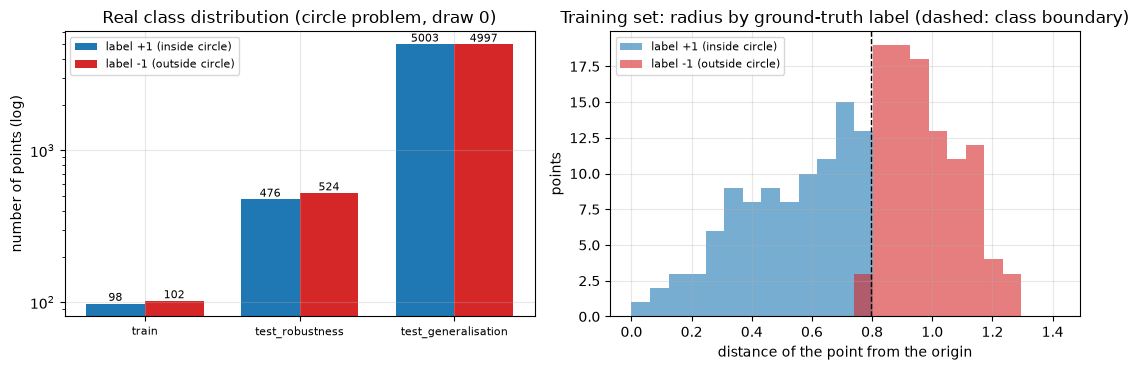

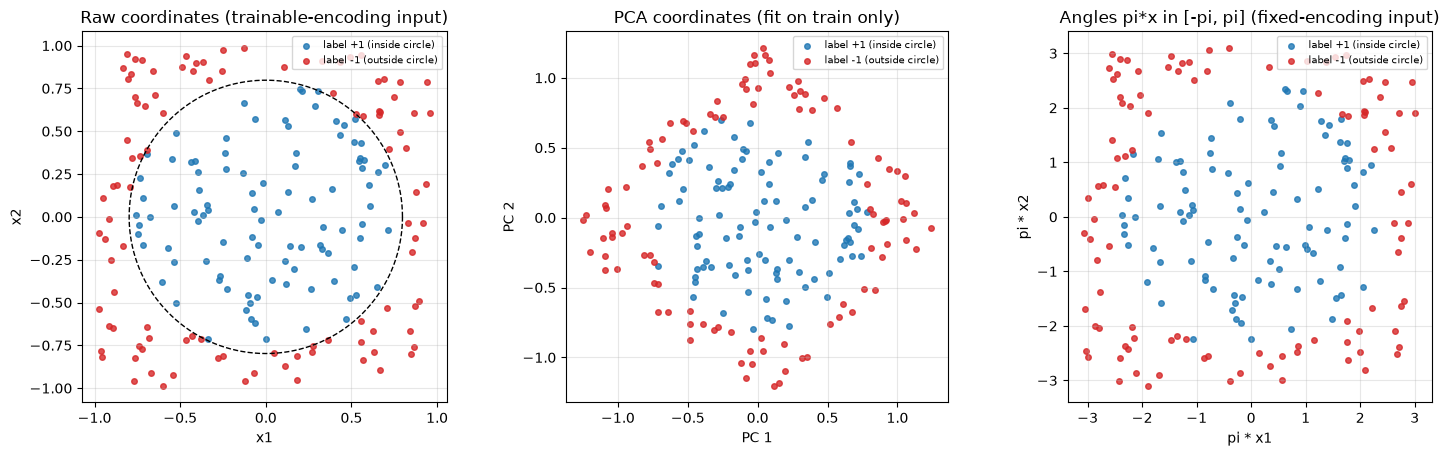

In [5]:
FEATURES = ["x1", "x2"]
DF = pd.DataFrame(np.vstack([Xtr, Xro, Xge]), columns=FEATURES)
DF["label"] = np.concatenate([ytr, yro, yge]).astype(int)
DF["split"] = ["train"] * len(ytr) + ["test_robustness"] * len(yro) + ["test_generalisation"] * len(yge)
DF["radius"] = np.sqrt((DF[FEATURES].values ** 2).sum(1))
print("dataset shape (all splits):", DF.shape, "| training set:", Xtr.shape, "| robustness test:", Xro.shape, "| generalisation test:", Xge.shape)
print("feature names:", FEATURES, "(+ derived radius, not used by any model)")
print("original label values:", sorted(DF["label"].unique().tolist()), "(+1 inside the circle, -1 outside)")
print(DF.groupby(["split", "label"]).size().unstack().rename(columns={-1: "label -1 (outside)", 1: "label +1 (inside)"}))
print("circle radius sqrt(2/pi) =", round(math.sqrt(CIRCLE_R2), 4), "| feature ranges:", DF[FEATURES].agg(["min", "max"]).round(3).to_dict())

pca = PCA(n_components=2, random_state=SEED).fit(Xtr)               # fitted on the training split only
Ztr = pca.transform(Xtr)
print("PCA explained variance (train):", pca.explained_variance_ratio_.round(4), "(about equal: uniform square, PCA is just a rotation)")
ANG_tr = np.pi * Xtr                                              # the fixed-encoding model's rotation angles
COLS = {1: "#1f77b4", -1: "#d62728"}; NAMES = {1: "label +1 (inside circle)", -1: "label -1 (outside circle)"}

# Figure 1: class distribution
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
sp = ["train", "test_robustness", "test_generalisation"]
w = 0.38
for i, lab in enumerate((1, -1)):
    cnt = [int(((DF["split"] == s) & (DF["label"] == lab)).sum()) for s in sp]
    b = ax[0].bar(np.arange(3) + (i - 0.5) * w, cnt, w, color=COLS[lab], label=NAMES[lab])
    for xx, v in zip(np.arange(3) + (i - 0.5) * w, cnt): ax[0].text(xx, v, str(v), ha="center", va="bottom", fontsize=8)
ax[0].set_xticks(range(3)); ax[0].set_xticklabels(sp, fontsize=8); ax[0].set_yscale("log"); ax[0].set_ylabel("number of points (log)")
ax[0].set_title("Real class distribution (circle problem, draw 0)"); ax[0].legend(fontsize=8)
for lab in (1, -1):
    ax[1].hist(DF.loc[(DF.split == "train") & (DF.label == lab), "radius"], bins=np.linspace(0, 1.42, 24), alpha=0.6, color=COLS[lab], label=NAMES[lab])
ax[1].axvline(math.sqrt(CIRCLE_R2), color="k", ls="--", lw=1); ax[1].set_xlabel("distance of the point from the origin"); ax[1].set_ylabel("points")
ax[1].set_title("Training set: radius by ground-truth label (dashed: class boundary)"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

# Figure 2: real observations coloured by ground-truth label
fig, ax = plt.subplots(1, 3, figsize=(15, 4.6))
th = np.linspace(0, 2 * np.pi, 300)
for lab in (1, -1):
    m = ytr == lab
    ax[0].scatter(Xtr[m, 0], Xtr[m, 1], s=16, color=COLS[lab], alpha=0.8, label=NAMES[lab])
    ax[1].scatter(Ztr[m, 0], Ztr[m, 1], s=16, color=COLS[lab], alpha=0.8, label=NAMES[lab])
    ax[2].scatter(ANG_tr[m, 0], ANG_tr[m, 1], s=16, color=COLS[lab], alpha=0.8, label=NAMES[lab])
ax[0].plot(math.sqrt(CIRCLE_R2) * np.cos(th), math.sqrt(CIRCLE_R2) * np.sin(th), "k--", lw=1)
ax[0].set_title("Raw coordinates (trainable-encoding input)"); ax[0].set_xlabel("x1"); ax[0].set_ylabel("x2")
ax[1].set_title("PCA coordinates (fit on train only)"); ax[1].set_xlabel("PC 1"); ax[1].set_ylabel("PC 2")
ax[2].set_title("Angles pi*x in [-pi, pi] (fixed-encoding input)"); ax[2].set_xlabel("pi * x1"); ax[2].set_ylabel("pi * x2")
for a in ax: a.legend(fontsize=7, loc="upper right"); a.set_aspect("equal", adjustable="box")
plt.tight_layout(); plt.show()

## Quantum Circuit Architecture

**What is executed.** Two gate-based models are trained and compared; each is drawn below from the **real PennyLane QNode** (`qml.draw_mpl`), with the parameters of an actual random initialisation so that the numbers on the gates are real values.

* **Trainable encoding** (eqs. 2 to 4, Fig. 7 of the paper): 3 qubits, 3 layers. In every layer each qubit gets `URot(alpha, beta, 0) = Rot(alpha, beta, 0)` with `alpha = w1.x + theta1`, `beta = w2.x + theta2` (`w1, w2 in R^2` trainable), followed by a ring of CNOTs `(0,1), (1,2), (2,0)`; measured observable `M = Z x Z x Z`. Trainable parameters: `18 gates x (2 weights + 1 offset) = 54`. The input `x` is loaded into **every** layer (data re-uploading).
* **Fixed encoding** (eq. 14, Fig. 4): the same 3 layers, but the data are loaded by `Rot(pi x1, pi x2, 0)` (fixed `w`, inputs rescaled to `[-pi, pi]`) and followed by a trainable `Rot(phi1, phi2, phi3)`; same CNOT ring and observable. Trainable parameters: `9 x 3 = 27`.

**Fast simulator and equivalence.** Training 100+ models with the QNode would take hours, so the training and evaluation code below uses a vectorised exact NumPy statevector simulator that applies the *same gate list* (`Rot` matrices as defined by PennyLane, the CNOT ring, `<ZZZ>`). The cell asserts that it equals the QNodes (`default.qubit` and the paper's `lightning.qubit`) in expectation value (`atol 1e-10`) and in gradient with respect to all parameters.

**Assumptions where the paper omits details.** The order of the CNOTs in the ring is not drawn in Fig. 7 (here `(0,1), (1,2), (2,0)`); the fixed-encoding model's exact layer layout is only described in words (here: encoding rotation, trainable rotation, ring); in the fixed model the same `Rot(pi x1, pi x2, 0)` is applied on every qubit and layer.

asserted: fast simulator == PennyLane default.qubit QNodes on 12 random points, both models: max |value difference| = 8.88e-16, max |gradient difference| = 8.60e-16


asserted: fast simulator == PennyLane lightning.qubit QNodes on 12 random points, both models: max |value difference| = 1.11e-15, max |gradient difference| = 9.71e-16
TRAINABLE encoding (54 trainable parameters, observable ZZZ): qubits = 3, depth = 12, gates = {'Rot': 9, 'CNOT': 9}, trainable parameters = 54


Matplotlib is building the font cache; this may take a moment.


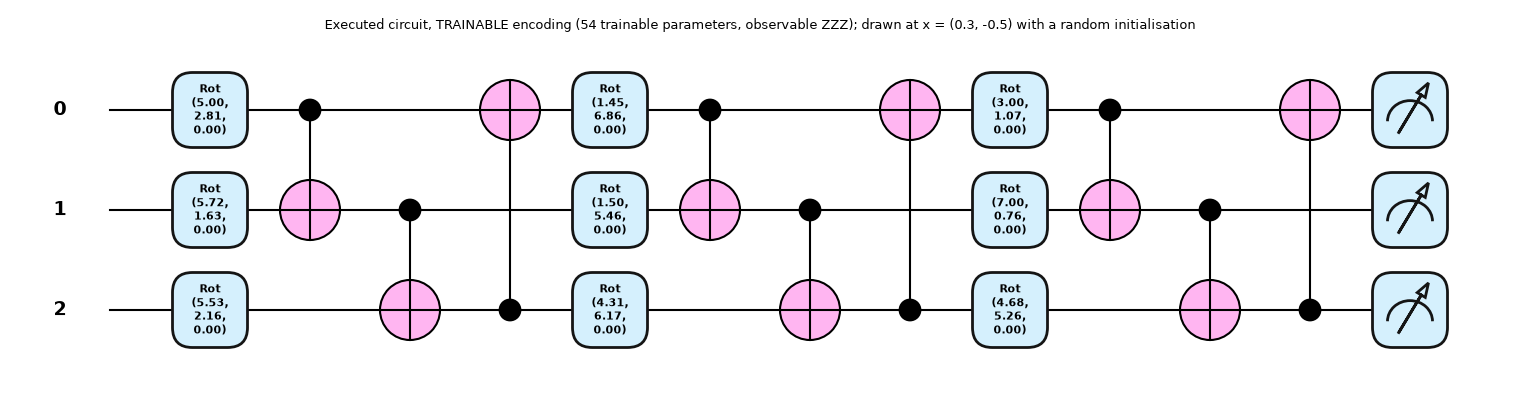

FIXED encoding (27 trainable parameters, observable ZZZ): qubits = 3, depth = 15, gates = {'Rot': 18, 'CNOT': 9}, trainable parameters = 27


Matplotlib is building the font cache; this may take a moment.


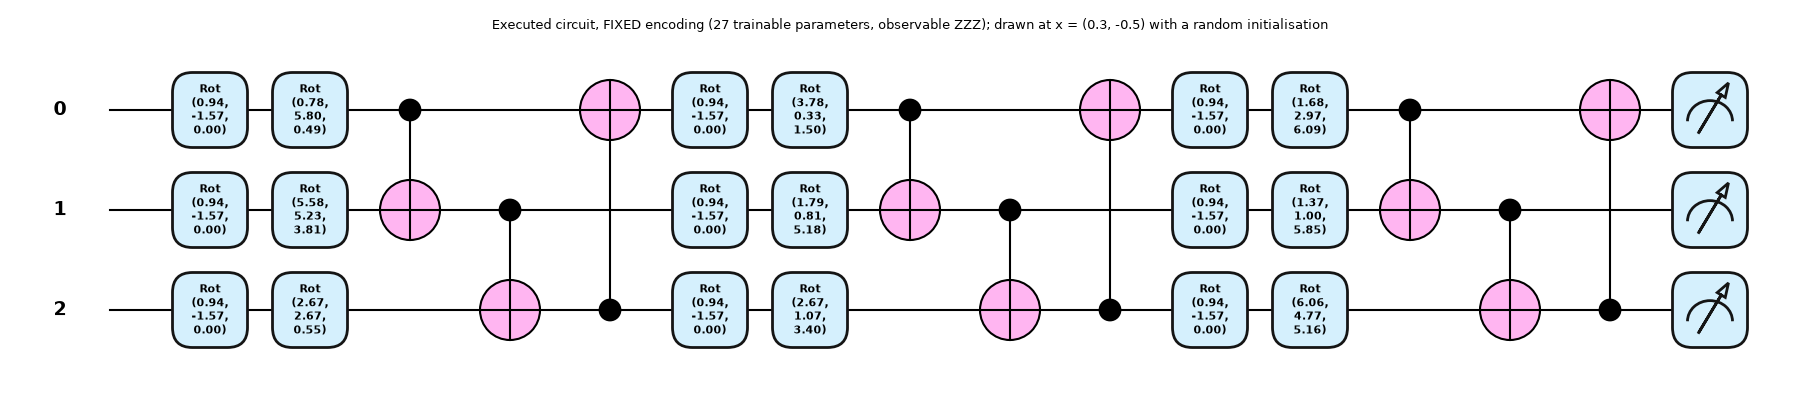

||H_j|| = 0.5 (Z/2 and Y/2), ||M|| = ||Z x Z x Z|| = 1.0, data-dependent rotations N = 18  ->  L = 2 ||M|| sum_j ||w_j|| ||H_j|| = 1.0 * sum_j ||w_j||
fixed encoding: every ||w_j|| = pi  ->  L_fixed = 56.55 (paper: 56.55)


In [6]:
# ---- exact vectorised statevector simulator (autograd-differentiable) ----
def rot_mat(phi, theta, omega):
    # PennyLane's qml.Rot(phi, theta, omega) = RZ(omega) RY(theta) RZ(phi); arrays of any shape -> (..., 2, 2)
    c = anp.cos(theta / 2); s = anp.sin(theta / 2)
    a = anp.exp(-0.5j * (phi + omega)); b = anp.exp(0.5j * (phi - omega))
    return anp.stack([anp.stack([a * c, -b * s], -1), anp.stack([anp.conj(b) * s, anp.conj(a) * c], -1)], -2)

def cnot_perm(c, t):
    p = np.zeros(8, int)
    for i in range(8):
        bits = [(i >> (2 - q)) & 1 for q in range(3)]       # qubit 0 is the most significant bit (PennyLane convention)
        if bits[c]: bits[t] ^= 1
        p[i] = sum(bit << (2 - q) for q, bit in enumerate(bits))
    return p
RING = [cnot_perm(q, (q + 1) % 3) for q in range(3)]       # CHOICE: ring (0,1), (1,2), (2,0)
SIGN = np.array([(-1) ** bin(i).count("1") for i in range(8)], float)   # eigenvalues of Z x Z x Z
E0 = np.eye(8)[0].astype(complex)                           # |000>

def layer_unitary(U):          # U (N,3,2,2): one single-qubit gate per qubit -> (N,8,8) = U0 (x) U1 (x) U2
    N = U.shape[0]
    K = (U[:, 0][:, :, None, :, None] * U[:, 1][:, None, :, None, :]).reshape(N, 4, 4)
    return (K[:, :, None, :, None] * U[:, 2][:, None, :, None, :]).reshape(N, 8, 8)

def run_layers(Ulayers):       # list of (N,3,2,2) -> <ZZZ>, shape (N,)
    N = Ulayers[0].shape[0]
    st = anp.zeros((N, 8), dtype=complex) + E0[None, :]
    for U in Ulayers:
        st = anp.matmul(layer_unitary(U), st[:, :, None])[:, :, 0]
        for p in RING: st = st[:, p]
    pr = anp.real(st * anp.conj(st))
    return anp.sum(pr * SIGN[None, :], axis=1)

P_TRAIN, P_FIXED = N_GATES * 3, L * NQ * 3                  # 54 and 27 trainable parameters
def fwd_train(v, x):           # v (R,54), x (B,2) -> (R,B): trainable-encoding model
    R, B = v.shape[0], x.shape[0]
    W = v[:, :N_GATES * 2].reshape(R, N_GATES, 2); TH = v[:, N_GATES * 2:]
    ang = (anp.matmul(x[None, :, :], anp.swapaxes(W, 1, 2)) + TH[:, None, :]).reshape(R * B, L, NQ, 2)
    U = rot_mat(ang[..., 0], ang[..., 1], 0.0 * ang[..., 0])
    return run_layers([U[:, l] for l in range(L)]).reshape(R, B)

def fwd_fixed(v, x):           # v (R,27), x (B,2) -> (R,B): fixed-encoding model, inputs rescaled to [-pi, pi]
    R, B = v.shape[0], x.shape[0]
    P = v.reshape(R, L, NQ, 3)
    Ue = rot_mat(np.pi * x[:, 0], np.pi * x[:, 1], 0.0 * x[:, 0])             # (B,2,2)
    Ut = rot_mat(P[..., 0], P[..., 1], P[..., 2])                             # (R,L,NQ,2,2)
    G = anp.matmul(Ut[:, None], Ue[None, :, None, None]).reshape(R * B, L, NQ, 2, 2)   # trainable rotation after encoding
    return run_layers([G[:, l] for l in range(L)]).reshape(R, B)

# ---- the real PennyLane QNodes (what the paper's code runs) ----
def make_qnodes(device_name, diff_method):
    dev = qml.device(device_name, wires=NQ)
    M = qml.PauliZ(0) @ qml.PauliZ(1) @ qml.PauliZ(2)
    @qml.qnode(dev, diff_method=diff_method)
    def qnode_train(x, W, TH):             # W (L,NQ,2,2): W[l,q,k] = encoding vector of angle k; TH (L,NQ,2)
        for l in range(L):
            for q in range(NQ):
                qml.Rot(x[0] * W[l, q, 0, 0] + x[1] * W[l, q, 0, 1] + TH[l, q, 0],
                        x[0] * W[l, q, 1, 0] + x[1] * W[l, q, 1, 1] + TH[l, q, 1], 0.0, wires=q)
            for q in range(NQ): qml.CNOT(wires=[q, (q + 1) % NQ])
        return qml.expval(M)
    @qml.qnode(dev, diff_method=diff_method)
    def qnode_fixed(x, P):                 # P (L,NQ,3)
        for l in range(L):
            for q in range(NQ):
                qml.Rot(np.pi * x[0], np.pi * x[1], 0.0, wires=q)             # fixed encoding
                qml.Rot(P[l, q, 0], P[l, q, 1], P[l, q, 2], wires=q)          # trainable rotation
            for q in range(NQ): qml.CNOT(wires=[q, (q + 1) % NQ])
        return qml.expval(M)
    return qnode_train, qnode_fixed

qt_def, qf_def = make_qnodes("default.qubit", "backprop")
qt_lgt, qf_lgt = make_qnodes("lightning.qubit", "adjoint")

rng_chk = np.random.default_rng(SEED + 7)
v_t = np.concatenate([rng_chk.uniform(-np.pi, np.pi, N_GATES * 2), rng_chk.uniform(0, 2 * np.pi, N_GATES)])
v_f = rng_chk.uniform(0, 2 * np.pi, P_FIXED)
Xchk = rng_chk.uniform(-1, 1, size=(12, 2))
from pennylane import numpy as pnp
for name, dev_t, dev_f in (("default.qubit", qt_def, qf_def), ("lightning.qubit", qt_lgt, qf_lgt)):
    worst_v, worst_g = 0.0, 0.0
    for x in Xchk:
        Wp = pnp.array(v_t[:36].reshape(L, NQ, 2, 2), requires_grad=True); THp = pnp.array(v_t[36:].reshape(L, NQ, 2), requires_grad=True)
        val = float(dev_t(pnp.array(x), Wp, THp))
        gW, gT = qml.grad(dev_t, argnums=(1, 2))(pnp.array(x), Wp, THp)
        mine = float(fwd_train(v_t[None], x[None])[0, 0])
        gmine = grad(lambda vv: anp.sum(fwd_train(vv[None], x[None])))(v_t)
        worst_v = max(worst_v, abs(val - mine)); worst_g = max(worst_g, np.abs(np.concatenate([np.ravel(gW), np.ravel(gT)]) - gmine).max())
        Pp = pnp.array(v_f.reshape(L, NQ, 3), requires_grad=True)
        valf = float(dev_f(pnp.array(x), Pp)); gP = qml.grad(dev_f, argnums=1)(pnp.array(x), Pp)
        minef = float(fwd_fixed(v_f[None], x[None])[0, 0]); gminef = grad(lambda vv: anp.sum(fwd_fixed(vv[None], x[None])))(v_f)
        worst_v = max(worst_v, abs(valf - minef)); worst_g = max(worst_g, np.abs(np.ravel(gP) - gminef).max())
    assert worst_v < 1e-10 and worst_g < 1e-8, (name, worst_v, worst_g)
    print(f"asserted: fast simulator == PennyLane {name} QNodes on {len(Xchk)} random points, both models: "
          f"max |value difference| = {worst_v:.2e}, max |gradient difference| = {worst_g:.2e}")

# ---- draw the circuits actually executed ----
Wd = pnp.array(v_t[:36].reshape(L, NQ, 2, 2)); THd = pnp.array(v_t[36:].reshape(L, NQ, 2)); xd = pnp.array([0.3, -0.5])
for tag, qn, args, npar in (("TRAINABLE encoding (54 trainable parameters, observable ZZZ)", qt_def, (xd, Wd, THd), 54),
                            ("FIXED encoding (27 trainable parameters, observable ZZZ)", qf_def, (xd, pnp.array(v_f.reshape(L, NQ, 3))), 27)):
    sp = qml.specs(qn)(*args)
    print(f"{tag}: qubits = {sp.num_device_wires}, depth = {sp.resources.depth}, gates = {dict(sp.resources.gate_types)}, trainable parameters = {npar}")
    fig, ax = qml.draw_mpl(qn, decimals=2, style="pennylane")(*args)
    fig.suptitle(f"Executed circuit, {tag}; drawn at x = (0.3, -0.5) with a random initialisation", fontsize=9)
    plt.show()
# Lipschitz-bound constants from the circuit's own generators: Rot(a, b, 0) = RY(b) RZ(a), RZ(a) = exp(-i a Z/2), RY(b) = exp(-i b Y/2)
Zm = np.diag([1., -1.]); Ym = np.array([[0, -1j], [1j, 0]])
H_NORM = float(np.linalg.norm(Zm / 2, 2)); assert abs(np.linalg.norm(Ym / 2, 2) - H_NORM) < 1e-12
M_NORM = float(np.abs(SIGN).max())
print(f"||H_j|| = {H_NORM} (Z/2 and Y/2), ||M|| = ||Z x Z x Z|| = {M_NORM}, data-dependent rotations N = {N_GATES}  ->  L = 2 ||M|| sum_j ||w_j|| ||H_j|| = {2 * M_NORM * H_NORM:.1f} * sum_j ||w_j||")
print("fixed encoding: every ||w_j|| = pi  ->  L_fixed =", round(2 * M_NORM * H_NORM * N_GATES * np.pi, 2), "(paper: 56.55)")

## 2. Training with the Lipschitz regulariser

**The cost (eq. 9).** `cost = mean_k (f(x_k) - y_k)^2 + lambda * sum_j ||w_j||^2 ||H_j||^2` with `||H_j|| = 1/2`. With `lambda = 0` this is ordinary least-squares training. The regulariser only touches the encoding weights `w_j`, not the offsets `theta_j`, because only `w_j` appears in the Lipschitz bound.

**Procedure (Appendix C).** ADAM with learning rate 0.1, 200 epochs, 12 random initialisations per `lambda`; after training, the parameters with the **lowest cost over all runs and all epochs** are kept (the cost includes the regulariser, so the selection uses the training set only). All initialisations are shared between values of `lambda`, and many models are trained at the same time as rows of one array.

`Lipschitz bound` below always means `L = 2 ||M|| sum_j ||w_j|| ||H_j|| = sum_j ||w_j||` (Euclidean norms, as in the paper).

In [7]:
# ---------------- training machinery ----------------
def reg_train(v): return H_NORM ** 2 * anp.sum(v[:, :N_GATES * 2] ** 2, axis=1)            # sum_j ||w_j||^2 ||H_j||^2
def reg_fixed(v): return anp.sum(v ** 2, axis=1)                                          # sum_j ||phi_j||^2   (eq. C5)
def lip_train(v):                                                                         # L = 2 ||M|| sum_j ||w_j|| ||H_j||
    W = np.asarray(v)[:, :N_GATES * 2].reshape(-1, N_GATES, 2)
    return 2 * M_NORM * H_NORM * np.sqrt((W ** 2).sum(-1)).sum(-1)
LIP_FIXED = 2 * M_NORM * H_NORM * N_GATES * np.pi                                         # all ||w_j|| = pi, independent of training

def adam_train(fwd, reg, v0, lam, X, y, epochs, lr, chunk=ROW_CHUNK, tag="", b1=0.9, b2=0.999, eps=1e-8):
    # Trains the rows of v0 independently (full batch). Returns the best parameters/cost of every row over all epochs and the cost history.
    R = v0.shape[0]
    best_v, best_c = v0.copy(), np.full(R, np.inf)
    hist_c, hist_m = np.zeros((epochs + 1, R)), np.zeros((epochs + 1, R))
    t0 = time.time()
    for s in range(0, R, chunk):
        idx = np.arange(s, min(R, s + chunk))
        v = v0[idx].copy(); lam_c = lam[idx]; m = np.zeros_like(v); u = np.zeros_like(v)
        store = {}
        def total(vv):
            f = fwd(vv, X)
            mse = anp.mean((f - y[None, :]) ** 2, axis=1)
            rc = mse + lam_c * reg(vv)
            store["rc"], store["mse"] = getval(rc), getval(mse)
            return anp.sum(rc)
        g = grad(total)
        for e in range(epochs + 1):
            gg = g(v)
            rc = store["rc"]; hist_c[e, idx] = rc; hist_m[e, idx] = store["mse"]
            better = rc < best_c[idx]
            if better.any():
                best_c[idx[better]] = rc[better]; best_v[idx[better]] = v[better]
            if e == epochs: break
            m = b1 * m + (1 - b1) * gg; u = b2 * u + (1 - b2) * gg ** 2
            v = v - lr * (m / (1 - b1 ** (e + 1))) / (np.sqrt(u / (1 - b2 ** (e + 1))) + eps)
    print(f"  [{tag}] trained {R} models x {epochs} epochs in {time.time() - t0:.0f} s")
    return best_v, best_c, hist_c, hist_m

def predict(fwd, v, X, budget=24000):
    v = np.atleast_2d(v); R = v.shape[0]; step = max(50, budget // R)
    return np.concatenate([np.asarray(fwd(v, X[i:i + step])) for i in range(0, len(X), step)], axis=1)
sgn = lambda f: np.where(f > 0, 1.0, -1.0)
def acc_of(fwd, v, X, y): return (sgn(predict(fwd, v, X)) == y[None, :]).mean(1)

def pick_best(best_v, best_c, lam_rows, lams, n_runs):
    # for every lambda: the run with minimal (regularised) training cost over all runs and epochs
    out = {}
    for lam in lams:
        rows = np.where(lam_rows == lam)[0]
        out[lam] = rows[np.argmin(best_c[rows])]
    return out

RES, BEST, HIST = [], {}, {}
T_TRAIN0 = time.time()
for d in range(N_DRAWS):
    Xt, yt = DRAWS[d]["train"]; Xg, yg = DRAWS[d]["gen"]
    nr = N_RUNS if d == 0 else N_RUNS_EXTRA
    rng_i = np.random.default_rng(SEED + 17 + d)
    init_t = np.hstack([rng_i.uniform(-INIT_W, INIT_W, (nr, N_GATES * 2)), rng_i.uniform(0, 2 * np.pi, (nr, N_GATES))])   # CHOICE
    init_f = rng_i.uniform(0, 2 * np.pi, (nr, P_FIXED))                                                                   # CHOICE
    for model, fwd, reg, lams, init, P in (("trainable", fwd_train, reg_train, LAMBDAS_GEN, init_t, P_TRAIN),
                                           ("fixed", fwd_fixed, reg_fixed, LAMBDAS_PHI, init_f, P_FIXED)):
        lam_rows = np.repeat(np.array(lams, float), nr); v0 = np.tile(init, (len(lams), 1))
        bv, bc, hc, hm = adam_train(fwd, reg, v0, lam_rows, Xt, yt, EPOCHS, LR, tag=f"draw {d}, {model}")
        sel = pick_best(bv, bc, lam_rows, lams, nr)
        for lam in lams:
            r = sel[lam]; v1 = bv[r][None]
            ftr, fte = predict(fwd, v1, Xt)[0], predict(fwd, v1, Xg)[0]
            RES.append(dict(draw=d, model=model, lam=lam, L=float(lip_train(v1)[0]) if model == "trainable" else LIP_FIXED,
                            train_acc=(sgn(ftr) == yt).mean(), test_acc=(sgn(fte) == yg).mean(),
                            train_mse=((ftr - yt) ** 2).mean(), test_mse=((fte - yg) ** 2).mean(), best_cost=bc[r],
                            mean_run_test_acc=float((sgn(predict(fwd, bv[np.where(lam_rows == lam)[0]], Xg)) == yg[None, :]).mean())))
            BEST[(d, model, lam)] = bv[r].copy()
        if d == 0: HIST[model] = (lam_rows, hc, hm, bc)
RES = pd.DataFrame(RES)
print(f"all training done in {(time.time() - T_TRAIN0) / 60:.1f} min")
print(RES[RES.draw == 0].round(4).to_string(index=False))

  [draw 0, trainable] trained 84 models x 200 epochs in 766 s


  [draw 0, fixed] trained 48 models x 200 epochs in 259 s


  [draw 1, trainable] trained 21 models x 200 epochs in 124 s


  [draw 1, fixed] trained 12 models x 200 epochs in 73 s


  [draw 2, trainable] trained 21 models x 200 epochs in 130 s


  [draw 2, fixed] trained 12 models x 200 epochs in 81 s


all training done in 25.0 min
 draw     model   lam       L  train_acc  test_acc  train_mse  test_mse  best_cost  mean_run_test_acc
    0 trainable 0.000 35.7001      0.950    0.9446     0.2588    0.2840     0.2588             0.9182
    0 trainable 0.050  4.3872      0.930    0.9099     0.3917    0.3983     0.4414             0.9343
    0 trainable 0.100  4.3619      0.945    0.9254     0.3953    0.4000     0.4902             0.9319
    0 trainable 0.150  4.2486      0.945    0.9371     0.4026    0.4050     0.5403             0.9410
    0 trainable 0.200  4.1671      0.960    0.9456     0.4082    0.4087     0.5854             0.9535
    0 trainable 0.300  4.0333      0.960    0.9486     0.4225    0.4195     0.6711             0.9076
    0 trainable 0.500  4.0556      0.900    0.9205     0.4957    0.4889     0.8292             0.8542
    0     fixed 0.000 56.5487      0.950    0.8890     0.3541    0.4104     0.3541             0.9026
    0     fixed 0.001 56.5487      0.945    0.9016  

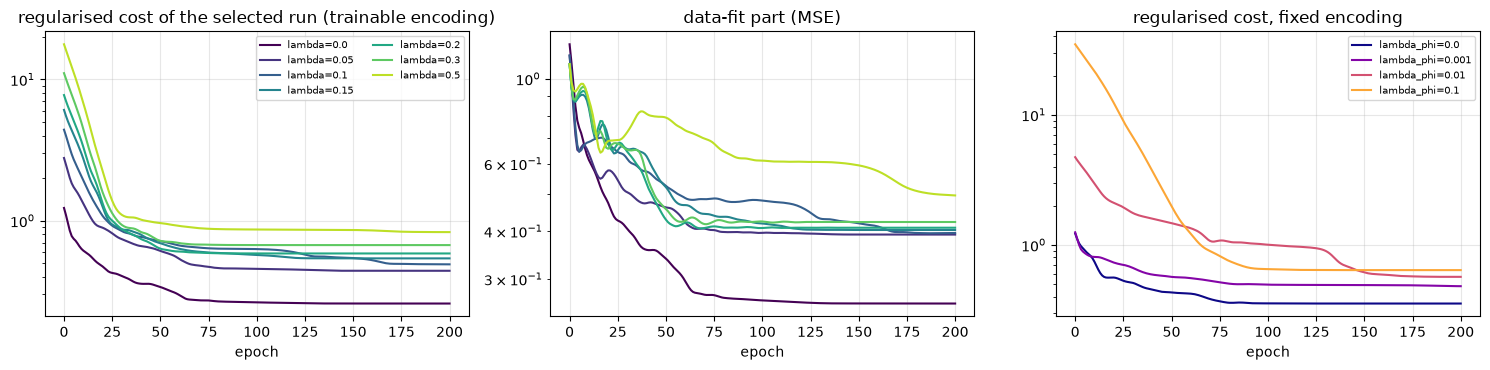

In [8]:
# Training curves of draw 0 (best run per lambda): total cost and its data-fit part
lam_rows, hc, hm, bc = HIST["trainable"]
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
cm = plt.cm.viridis(np.linspace(0, 0.9, len(LAMBDAS_GEN)))
for lam, col in zip(LAMBDAS_GEN, cm):
    rows = np.where(lam_rows == lam)[0]; r = rows[np.argmin(bc[rows])]
    ax[0].plot(hc[:, r], color=col, label=f"lambda={lam}"); ax[1].plot(hm[:, r], color=col)
ax[0].set_title("regularised cost of the selected run (trainable encoding)"); ax[1].set_title("data-fit part (MSE)")
ax[0].set_yscale("log"); ax[1].set_yscale("log"); ax[0].set_xlabel("epoch"); ax[1].set_xlabel("epoch"); ax[0].legend(fontsize=7, ncol=2)
lamf, hcf, hmf, bcf = HIST["fixed"]
for lam, col in zip(LAMBDAS_PHI, plt.cm.plasma(np.linspace(0, 0.8, len(LAMBDAS_PHI)))):
    rows = np.where(lamf == lam)[0]; r = rows[np.argmin(bcf[rows])]; ax[2].plot(hcf[:, r], color=col, label=f"lambda_phi={lam}")
ax[2].set_yscale("log"); ax[2].set_xlabel("epoch"); ax[2].set_title("regularised cost, fixed encoding"); ax[2].legend(fontsize=7)
plt.tight_layout(); plt.show()

## 3. Robustness: re-drawing Fig. 2

**Protocol (Section III, Fig. 2).** Every test point (1000) is perturbed by 200 independent noise vectors drawn uniformly from `[-e, +e]^2`. The paper's wording is "the worst case over 200 noise samples per data point", so a point counts as *correctly classified* only if it is correct for **all** noise samples (reading **A**, the literal one and the one used for the verdicts); this approximates the accuracy against attacks bounded by `e` in the max-norm. Because the wording could also mean "the worst test-set accuracy over the noise realisations", the notebook also draws reading **B** (each realisation perturbs the whole test set, the lowest of the first 20 realisations is reported) and shows the verdicts under both. The same noise is used for every model. Points that already failed are not simulated again (same result, less compute). The four models are the trainable encoding with `lambda` in `{0, 0.2, 0.5}` and the fixed encoding (unregularised). In the full run the same evaluation is repeated for the models of the further training sets (with fewer noise samples) to see how stable the picture is. The right panel shows the Lipschitz bounds on a log scale.

robustness evaluation done in 3.1 min
A) worst-case test accuracy PER POINT (a point is correct only if all noise samples are), draw 0 (paper protocol):
               lambda = 0.0  lambda = 0.2  lambda = 0.5  fixed encoding
noise level e                                                          
0.00                  0.942         0.949         0.921           0.879
0.05                  0.847         0.850         0.812           0.750
0.10                  0.712         0.724         0.673           0.595
0.15                  0.577         0.586         0.549           0.435
0.20                  0.426         0.447         0.406           0.292
0.30                  0.167         0.224         0.230           0.108
0.40                  0.068         0.092         0.108           0.051
0.50                  0.022         0.027         0.038           0.007
0.75                  0.000         0.000         0.000           0.000
1.00                  0.000         0.000         0.000

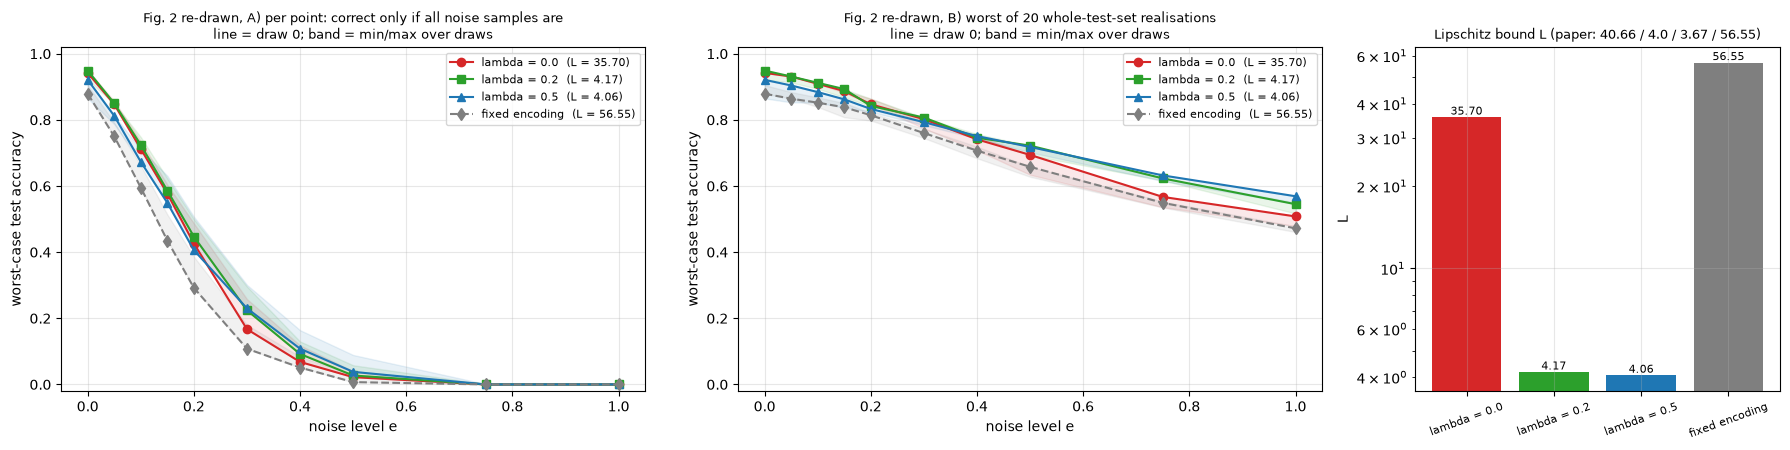

In [9]:
NOISE_BLOCK = 20
def robust_curve(fsign, X, y, eps_grid, n_noise, seed):
    # Returns two curves.
    # A ("per point", the paper's wording): a point counts as correct only if ALL n_noise perturbed copies are classified correctly.
    # B ("per realisation", alternative reading): every noise realisation perturbs the whole test set; the accuracy of the worst of
    #    the first NOISE_BLOCK realisations. Both use the same noise for every model. For A, points that already failed are not
    #    evaluated again (the result is identical, only cheaper).
    A, B = [], []
    n = len(X)
    for k, e in enumerate(eps_grid):
        if e == 0:
            a = (fsign(X) == y).mean(); A.append(a); B.append(a); continue
        alive = np.ones(n, bool)
        for blk in range(0, n_noise, NOISE_BLOCK):
            nb_ = min(NOISE_BLOCK, n_noise - blk)
            noise = np.random.default_rng(seed + 1000 * k + blk).uniform(-e, e, size=(nb_, n, 2))
            idx = np.arange(n) if blk == 0 else np.where(alive)[0]
            if len(idx) == 0: break
            ok = (fsign((X[idx][None] + noise[:, idx]).reshape(-1, 2)).reshape(nb_, len(idx)) == y[idx][None, :])
            if blk == 0: B.append(ok.mean(1).min())
            alive[idx] &= ok.all(0)
        A.append(alive.mean())
    return np.array(A), np.array(B)

MODELS_ROB = [("trainable", lam) for lam in LAMBDAS_ROB] + [("fixed", 0.0)]
FWD = {"trainable": fwd_train, "fixed": fwd_fixed}
ROB, ROBS = {}, {}
t0 = time.time()
for d in range(N_DRAWS):
    Xr, yr = DRAWS[d]["rob"]; nn = N_NOISE if d == 0 else N_NOISE_EXTRA
    for model, lam in MODELS_ROB:
        v1 = BEST[(d, model, lam)][None]
        ROB[(d, model, lam)], ROBS[(d, model, lam)] = robust_curve(lambda Z: sgn(predict(FWD[model], v1, Z)[0]), Xr, yr, EPS_GRID, nn, SEED + 500 + d)
print(f"robustness evaluation done in {(time.time() - t0) / 60:.1f} min")
LBL = {("trainable", 0.0): "lambda = 0.0", ("trainable", 0.2): "lambda = 0.2", ("trainable", 0.5): "lambda = 0.5", ("fixed", 0.0): "fixed encoding"}
STY = {("trainable", 0.0): ("#d62728", "o-"), ("trainable", 0.2): ("#2ca02c", "s-"), ("trainable", 0.5): ("#1f77b4", "^-"), ("fixed", 0.0): ("#7f7f7f", "d--")}
rob_df = pd.DataFrame({LBL[k]: ROB[(0,) + k] for k in MODELS_ROB}, index=EPS_GRID); rob_df.index.name = "noise level e"
robs_df = pd.DataFrame({LBL[k]: ROBS[(0,) + k] for k in MODELS_ROB}, index=EPS_GRID); robs_df.index.name = "noise level e"
print("A) worst-case test accuracy PER POINT (a point is correct only if all noise samples are), draw 0 (paper protocol):"); print(rob_df.round(3).to_string())
print(f"B) worst test-set accuracy over {NOISE_BLOCK} whole-test-set noise realisations (alternative reading of the paper's wording), draw 0:"); print(robs_df.round(3).to_string())
if N_DRAWS > 1:
    mean_df = pd.DataFrame({LBL[k]: np.mean([ROB[(d,) + k] for d in range(N_DRAWS)], 0) for k in MODELS_ROB}, index=EPS_GRID)
    means_df = pd.DataFrame({LBL[k]: np.mean([ROBS[(d,) + k] for d in range(N_DRAWS)], 0) for k in MODELS_ROB}, index=EPS_GRID)
    print(f"A) mean over the {N_DRAWS} training sets:"); print(mean_df.round(3).to_string())
else:
    mean_df, means_df = rob_df, robs_df

fig, ax = plt.subplots(1, 3, figsize=(18, 4.6), gridspec_kw={"width_ratios": [1.6, 1.6, 1]})
for j, (store, ttl) in enumerate(((ROB, "A) per point: correct only if all noise samples are"), (ROBS, f"B) worst of {NOISE_BLOCK} whole-test-set realisations"))):
    for k in MODELS_ROB:
        c, st = STY[k]
        ax[j].plot(EPS_GRID, store[(0,) + k], st, color=c, label=LBL[k] + f"  (L = {lip_train(BEST[(0,) + k][None])[0] if k[0] == 'trainable' else LIP_FIXED:.2f})")
        if N_DRAWS > 1:
            ar = np.array([store[(d,) + k] for d in range(N_DRAWS)]); ax[j].fill_between(EPS_GRID, ar.min(0), ar.max(0), color=c, alpha=0.10)
    ax[j].set_xlabel("noise level e"); ax[j].set_ylabel("worst-case test accuracy"); ax[j].set_ylim(-0.02, 1.02); ax[j].legend(fontsize=8)
    ax[j].set_title("Fig. 2 re-drawn, " + ttl + ("\nline = draw 0; band = min/max over draws" if N_DRAWS > 1 else ""), fontsize=9)
Ls = [lip_train(BEST[(0,) + k][None])[0] if k[0] == "trainable" else LIP_FIXED for k in MODELS_ROB]
bars = ax[2].bar(range(4), Ls, color=[STY[k][0] for k in MODELS_ROB]); ax[2].set_yscale("log"); ax[2].set_xticks(range(4)); ax[2].set_xticklabels([LBL[k] for k in MODELS_ROB], rotation=20, fontsize=8)
for i, v_ in enumerate(Ls): ax[2].text(i, v_, f"{v_:.2f}", ha="center", va="bottom", fontsize=8)
ax[2].set_title("Lipschitz bound L (paper: 40.66 / 4.0 / 3.67 / 56.55)", fontsize=9); ax[2].set_ylabel("L")
plt.tight_layout(); plt.show()

## 4. Generalisation: re-drawing Fig. 3

The same training setup is evaluated on 10 000 fresh test points for a range of `lambda`. According to Theorem IV.1 the generalisation error is bounded by `C1 ||M|| sum ||w_j|| ||H_j|| + C2 / sqrt(n)`, so a smaller `L` should help until the model becomes too weak to fit the training data. The paper reports a maximum test accuracy at `lambda = 0.15`, accuracies between 0.88 and 1.00, and a `L` that decreases with `lambda`. The left panel shows draw 0 (paper protocol, selected model out of 12 restarts) and, in the full run, the mean and standard deviation over all training-set draws; the right panel plots the generalisation gap against the Lipschitz bound, which is what the theorem is about (the constants `C1`, `C2` are not given in the paper, so only the *trend* can be checked).

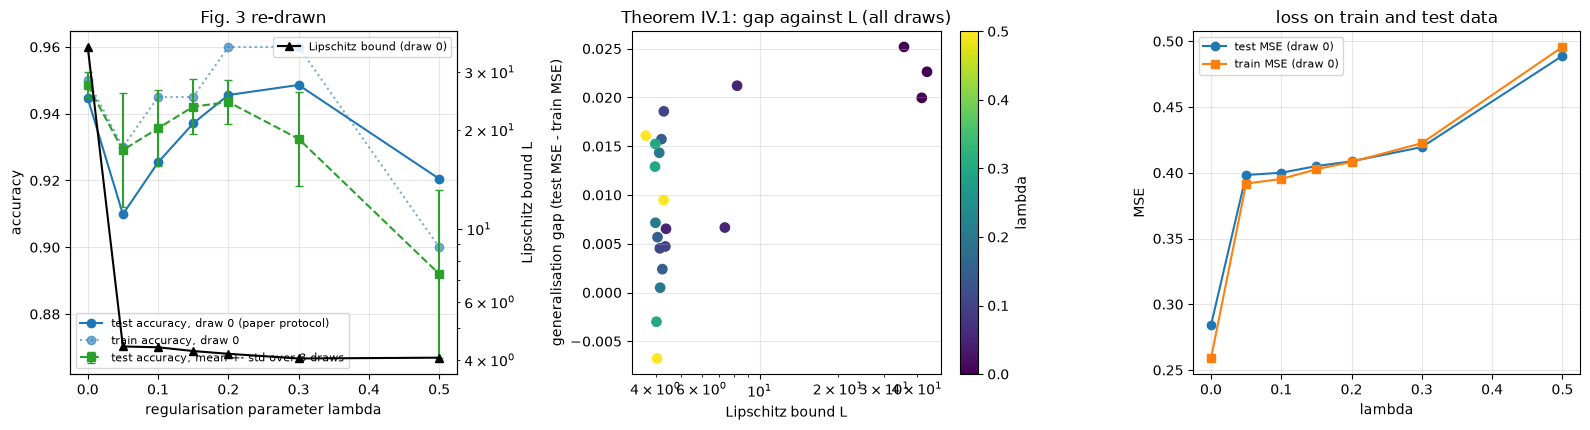

 lam  test_mean  test_std  train_mean  L_mean  L_std  runmean
0.00     0.9485    0.0039      0.9633 40.3917 4.1805   0.9243
0.05     0.9291    0.0170      0.9500  6.6535 2.0071   0.9357
0.10     0.9356    0.0114      0.9517  4.2732 0.1070   0.9362
0.15     0.9421    0.0082      0.9600  4.1780 0.0942   0.9380
0.20     0.9435    0.0067      0.9617  4.0995 0.0896   0.9410
0.30     0.9325    0.0140      0.9417  4.0032 0.0266   0.9209
0.50     0.8920    0.0253      0.8833  4.0087 0.3150   0.8559
Spearman correlation between L and the generalisation gap (all draws and lambdas): rho = 0.404, p = 0.0694
lambda with the highest test accuracy: draw 0 -> 0.3, mean over draws -> 0.0 (paper: 0.15)


In [10]:
TR = RES[RES.model == "trainable"].copy()
g = TR.groupby("lam").agg(test_mean=("test_acc", "mean"), test_std=("test_acc", "std"), train_mean=("train_acc", "mean"),
                          L_mean=("L", "mean"), L_std=("L", "std"), runmean=("mean_run_test_acc", "mean")).reset_index()
d0 = TR[TR.draw == 0].sort_values("lam")
fig, ax = plt.subplots(1, 3, figsize=(16, 4.4))
ax[0].plot(d0.lam, d0.test_acc, "o-", color="#1f77b4", label="test accuracy, draw 0 (paper protocol)")
ax[0].plot(d0.lam, d0.train_acc, "o:", color="#1f77b4", alpha=0.6, label="train accuracy, draw 0")
if N_DRAWS > 1:
    ax[0].errorbar(g.lam, g.test_mean, yerr=g.test_std.fillna(0), fmt="s--", color="#2ca02c", capsize=3, label=f"test accuracy, mean +- std over {N_DRAWS} draws")
ax[0].set_xlabel("regularisation parameter lambda"); ax[0].set_ylabel("accuracy"); ax[0].legend(fontsize=8, loc="lower left")
ax2 = ax[0].twinx(); ax2.plot(d0.lam, d0.L, "k^-", label="Lipschitz bound (draw 0)"); ax2.set_yscale("log"); ax2.set_ylabel("Lipschitz bound L"); ax2.grid(False); ax2.legend(fontsize=8, loc="upper right")
ax[0].set_title("Fig. 3 re-drawn")
gap = TR.test_mse - TR.train_mse
sc = ax[1].scatter(TR.L, gap, c=TR.lam, cmap="viridis", s=45); plt.colorbar(sc, ax=ax[1], label="lambda")
ax[1].set_xscale("log"); ax[1].set_xlabel("Lipschitz bound L"); ax[1].set_ylabel("generalisation gap (test MSE - train MSE)"); ax[1].set_title("Theorem IV.1: gap against L (all draws)")
rho_gap = spearmanr(TR.L, gap)
ax[2].plot(TR[TR.draw == 0].sort_values("lam").lam, TR[TR.draw == 0].sort_values("lam").test_mse, "o-", label="test MSE (draw 0)")
ax[2].plot(TR[TR.draw == 0].sort_values("lam").lam, TR[TR.draw == 0].sort_values("lam").train_mse, "s-", label="train MSE (draw 0)")
ax[2].set_xlabel("lambda"); ax[2].set_ylabel("MSE"); ax[2].set_title("loss on train and test data"); ax[2].legend(fontsize=8)
plt.tight_layout(); plt.show()
print(g.round(4).to_string(index=False))
print(f"Spearman correlation between L and the generalisation gap (all draws and lambdas): rho = {rho_gap.statistic:.3f}, p = {rho_gap.pvalue:.3g}")
lam_best0 = float(d0.loc[d0.test_acc.idxmax(), "lam"]); lam_best_mean = float(g.loc[g.test_mean.idxmax(), "lam"])
print(f"lambda with the highest test accuracy: draw 0 -> {lam_best0}, mean over draws -> {lam_best_mean} (paper: 0.15)")

## 5. Decision boundaries: re-drawing Fig. 5

The paper shows that the boundary of the regularised model is smoother than that of the unregularised one and that the fixed-encoding model cannot capture the circle. The panels show the sign of `f(x)` (background: `f`, black line: decision boundary `f = 0`), the true circle (dashed) and the 200 training points (small circles, coloured by their label). As in the paper, the displayed models are the selected (lowest-cost) ones.

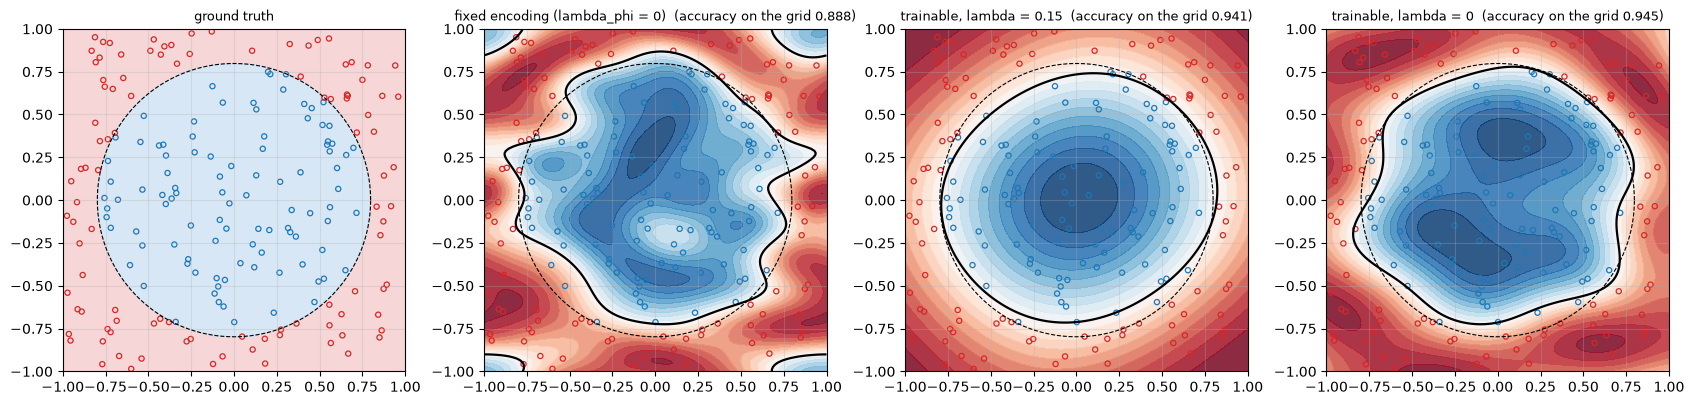

mean gradient magnitude of f over the square (a smoothness proxy, smaller = smoother): {'trainable 0.0': 2.29, 'trainable 0.15': 1.694, 'fixed 0.0': 2.842}


In [11]:
gx = np.linspace(-1, 1, 161); GX, GY = np.meshgrid(gx, gx); GRID = np.column_stack([GX.ravel(), GY.ravel()])
panels = [("ground truth", None), ("fixed encoding (lambda_phi = 0)", ("fixed", 0.0)), ("trainable, lambda = 0.15", ("trainable", 0.15)), ("trainable, lambda = 0", ("trainable", 0.0))]
fig, ax = plt.subplots(1, 4, figsize=(17, 4.4))
th = np.linspace(0, 2 * np.pi, 300)
FG = {}
for a, (title, key) in zip(ax, panels):
    if key is None:
        Z = circle_label(GRID).reshape(GX.shape); a.contourf(GX, GY, Z, levels=[-2, 0, 2], colors=["#f4cccc", "#cfe2f3"], alpha=0.8)
        acc_txt = ""
    else:
        v1 = BEST[(0,) + key][None]; f = predict(FWD[key[0]], v1, GRID)[0]; FG[key] = f
        Z = f.reshape(GX.shape); im = a.contourf(GX, GY, Z, levels=np.linspace(-1, 1, 21), cmap="RdBu", alpha=0.85); a.contour(GX, GY, Z, levels=[0], colors="k", linewidths=1.6)
        acc_txt = f"  (accuracy on the grid {(sgn(f) == circle_label(GRID)).mean():.3f})"
    a.plot(math.sqrt(CIRCLE_R2) * np.cos(th), math.sqrt(CIRCLE_R2) * np.sin(th), "k--", lw=0.8)
    for lab in (1, -1):
        m = ytr == lab; a.scatter(Xtr[m, 0], Xtr[m, 1], s=14, facecolors="none", edgecolors=COLS[lab], linewidths=0.9)
    a.set_title(title + acc_txt, fontsize=9); a.set_aspect("equal", adjustable="box"); a.set_xlim(-1, 1); a.set_ylim(-1, 1)
plt.tight_layout(); plt.show()
rough = {}
for key in (("trainable", 0.0), ("trainable", 0.15), ("fixed", 0.0)):
    f = FG[key].reshape(GX.shape); step = gx[1] - gx[0]
    gy_, gx_ = np.gradient(f, step); rough[key] = float(np.sqrt(gx_ ** 2 + gy_ ** 2).mean())
print("mean gradient magnitude of f over the square (a smoothness proxy, smaller = smoother):", {f"{k[0]} {k[1]}": round(v, 3) for k, v in rough.items()})

## 6. Fixed encodings: regularising the rotation angles instead (Appendix C.2, Fig. 6)

For the fixed-encoding model `L = 18 pi` regardless of training, so the Lipschitz regularisation is impossible. The paper checks whether regularising the *trainable rotation angles* `phi` (cost `+ lambda sum_j ||phi_j||^2`, eq. C5) helps generalisation anyway. It reports that `L` is constant, that the test accuracy is much lower than for the trainable encoding, and that its dependence on `lambda` is much weaker.

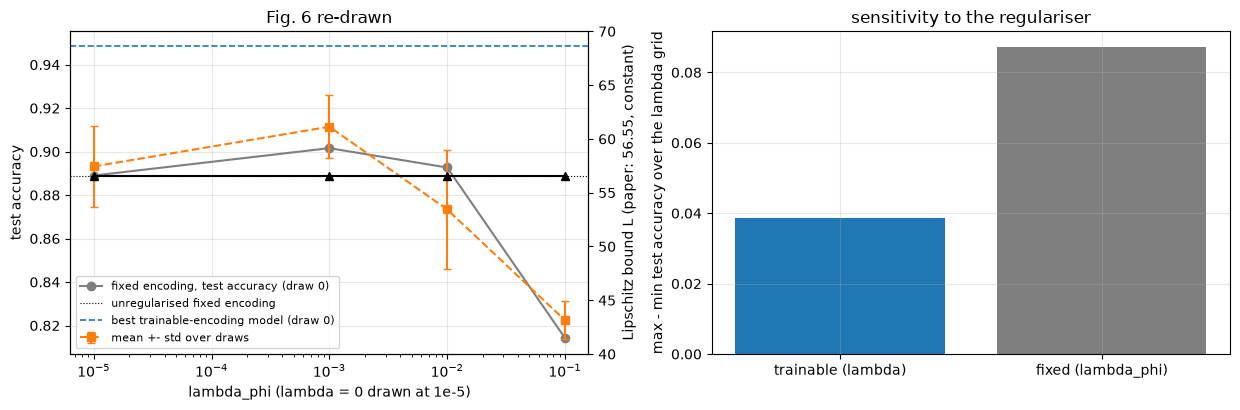

 draw model   lam       L  train_acc  test_acc  train_mse  test_mse  best_cost  mean_run_test_acc
    0 fixed 0.000 56.5487      0.950    0.8890     0.3541    0.4104     0.3541             0.9026
    0 fixed 0.001 56.5487      0.945    0.9016     0.3713    0.3966     0.4812             0.9015
    0 fixed 0.010 56.5487      0.905    0.8927     0.4265    0.4302     0.5678             0.8806
    0 fixed 0.100 56.5487      0.830    0.8143     0.5807    0.5995     0.6396             0.8142
                                            trainable encoding (all lambda)  fixed encoding (all lambda_phi)
range of test accuracy over lambda, draw 0                           0.0387                           0.0873


In [12]:
FX = RES[RES.model == "fixed"].copy()
gf = FX.groupby("lam").agg(test_mean=("test_acc", "mean"), test_std=("test_acc", "std"), L_mean=("L", "mean")).reset_index()
f0 = FX[FX.draw == 0].sort_values("lam")
fig, ax = plt.subplots(1, 2, figsize=(12.5, 4.2))
xs = np.where(f0.lam.values > 0, f0.lam.values, 1e-5)
ax[0].plot(xs, f0.test_acc, "o-", color="#7f7f7f", label="fixed encoding, test accuracy (draw 0)")
if N_DRAWS > 1:
    xm = np.where(gf.lam.values > 0, gf.lam.values, 1e-5); ax[0].errorbar(xm, gf.test_mean, yerr=gf.test_std.fillna(0), fmt="s--", color="#ff7f0e", capsize=3, label="mean +- std over draws")
ax[0].axhline(f0.test_acc.iloc[0], color="k", lw=0.8, ls=":", label="unregularised fixed encoding")
ax[0].axhline(d0.test_acc.max(), color="#1f77b4", lw=1.2, ls="--", label="best trainable-encoding model (draw 0)")
ax[0].set_xscale("log"); ax[0].set_xlabel("lambda_phi (lambda = 0 drawn at 1e-5)"); ax[0].set_ylabel("test accuracy"); ax[0].legend(fontsize=8)
ax2 = ax[0].twinx(); ax2.plot(xs, f0.L, "k^-"); ax2.set_ylim(40, 70); ax2.set_ylabel("Lipschitz bound L (paper: 56.55, constant)"); ax2.grid(False)
ax[0].set_title("Fig. 6 re-drawn")
rng_range = pd.DataFrame({"trainable encoding (all lambda)": [d0.test_acc.max() - d0.test_acc.min()], "fixed encoding (all lambda_phi)": [f0.test_acc.max() - f0.test_acc.min()]}, index=["range of test accuracy over lambda, draw 0"])
ax[1].bar([0, 1], [d0.test_acc.max() - d0.test_acc.min(), f0.test_acc.max() - f0.test_acc.min()], color=["#1f77b4", "#7f7f7f"])
ax[1].set_xticks([0, 1]); ax[1].set_xticklabels(["trainable (lambda)", "fixed (lambda_phi)"]); ax[1].set_ylabel("max - min test accuracy over the lambda grid"); ax[1].set_title("sensitivity to the regulariser")
plt.tight_layout(); plt.show()
print(f0.round(4).to_string(index=False)); print(rng_range.round(4).to_string())

## 7. Is the Lipschitz bound true, and how tight is it?

The theory says `|f(x) - f(x')| <= L ||x - x'||` for **every** pair of inputs. Two direct tests on the selected draw-0 models: (a) the largest gradient norm `||grad_x f||_2` over many random inputs is a lower estimate of the true Lipschitz constant and must not exceed `L`; (b) for random pairs `(x, x + delta)` with `||delta||` between 0.01 and 1, the ratio `|f(x+delta) - f(x)| / (L ||delta||)` must never exceed 1. The bound is a worst case over *all* inputs and all circuit parameters, so it may be loose; the plot shows how loose.

    model   lam  L_bound  max_grad_norm  tightness  max_pair_ratio
trainable 0.000  35.7001         4.9962     0.1400          0.1391
trainable 0.050   4.3872         2.3105     0.5266          0.5203
trainable 0.100   4.3619         2.2771     0.5220          0.5163
trainable 0.150   4.2486         2.2407     0.5274          0.5214
trainable 0.200   4.1671         2.2089     0.5301          0.5247
trainable 0.300   4.0333         2.1505     0.5332          0.5293
trainable 0.500   4.0556         1.8508     0.4564          0.4559
    fixed 0.000  56.5487         7.3001     0.1291          0.1180
    fixed 0.001  56.5487         7.1726     0.1268          0.1195
    fixed 0.010  56.5487         5.6078     0.0992          0.0882
    fixed 0.100  56.5487         7.5399     0.1333          0.1232
asserted: empirical gradient norm <= L and |f(x+d)-f(x)| <= L ||d|| for all tested models and pairs


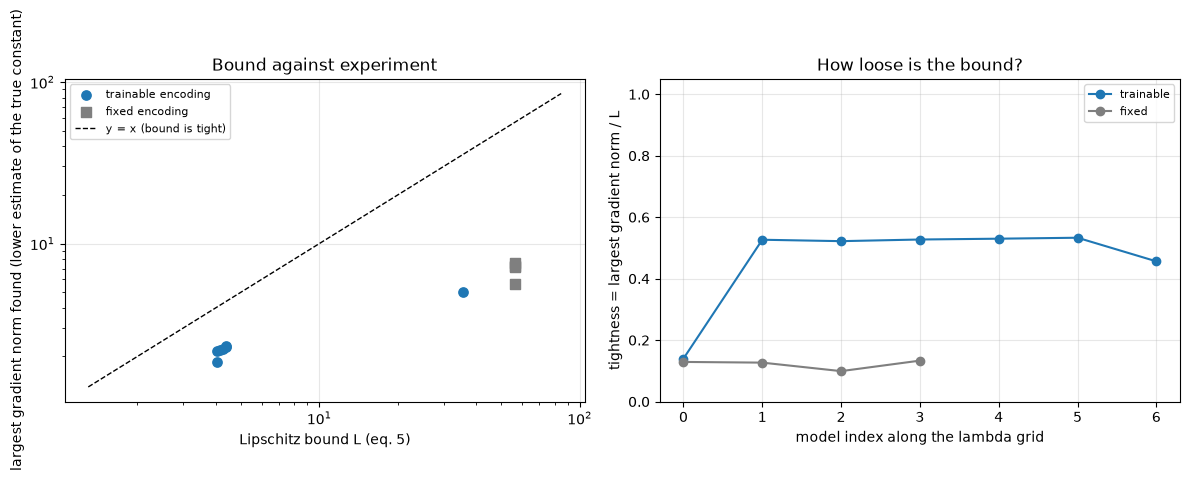

In [13]:
rng_b = np.random.default_rng(SEED + 99)
Xb = rng_b.uniform(-1, 1, size=(4000, 2))
dirs = rng_b.normal(size=Xb.shape); dirs /= np.linalg.norm(dirs, axis=1, keepdims=True)
mags = rng_b.choice([0.01, 0.05, 0.2, 0.5, 1.0], size=len(Xb)); X2 = Xb + mags[:, None] * dirs
rows = []
for model, lam in [("trainable", l) for l in LAMBDAS_GEN] + [("fixed", l) for l in LAMBDAS_PHI]:
    v1 = BEST[(0, model, lam)][None]; fw = FWD[model]
    gxx = grad(lambda z: anp.sum(fw(v1, z)))(Xb)                  # samples are independent, so this is the per-sample gradient
    emp = np.linalg.norm(gxx, axis=1).max()
    Lb = float(lip_train(v1)[0]) if model == "trainable" else LIP_FIXED
    ratio = np.abs(predict(fw, v1, X2)[0] - predict(fw, v1, Xb)[0]) / (Lb * mags)
    rows.append(dict(model=model, lam=lam, L_bound=Lb, max_grad_norm=emp, tightness=emp / Lb, max_pair_ratio=ratio.max()))
BND = pd.DataFrame(rows)
print(BND.round(4).to_string(index=False))
assert (BND.max_grad_norm <= BND.L_bound + 1e-9).all() and (BND.max_pair_ratio <= 1 + 1e-9).all(), "Lipschitz bound violated"
print("asserted: empirical gradient norm <= L and |f(x+d)-f(x)| <= L ||d|| for all tested models and pairs")
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
for model, mk, col in (("trainable", "o", "#1f77b4"), ("fixed", "s", "#7f7f7f")):
    s_ = BND[BND.model == model]; ax[0].scatter(s_.L_bound, s_.max_grad_norm, marker=mk, color=col, s=45, label=model + " encoding")
lim = [BND.max_grad_norm.min() * 0.7, BND.L_bound.max() * 1.5]; ax[0].plot(lim, lim, "k--", lw=1, label="y = x (bound is tight)")
ax[0].set_xscale("log"); ax[0].set_yscale("log"); ax[0].set_xlabel("Lipschitz bound L (eq. 5)"); ax[0].set_ylabel("largest gradient norm found (lower estimate of the true constant)")
ax[0].set_title("Bound against experiment"); ax[0].legend(fontsize=8)
for model, col in (("trainable", "#1f77b4"), ("fixed", "#7f7f7f")):
    s_ = BND[BND.model == model]; ax[1].plot(range(len(s_)), s_.tightness, "o-", color=col, label=model)
ax[1].set_xlabel("model index along the lambda grid"); ax[1].set_ylabel("tightness = largest gradient norm / L"); ax[1].set_ylim(0, 1.05); ax[1].set_title("How loose is the bound?"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

## 8. Extra check: a gradient attack instead of random noise

The paper's "worst case over 200 random noise samples" is only a proxy for an adversary. Here a **projected gradient descent (PGD)** attack in the max-norm ball of radius `e` (10 steps, step `2.5 e / 10`, random start) tries to maximise the squared error of each test point; a point counts as robust only if it is classified correctly at the start and after every step. This is an addition to the paper (`# CHOICE:` for all attack hyper-parameters) and is evaluated on the first test points of draw 0 for the same four models.

PGD robust accuracy on the first 500 test points (done in 28 s):
               lambda = 0.0  lambda = 0.2  lambda = 0.5  fixed encoding
noise level e                                                          
0.00                  0.944         0.952         0.916           0.884
0.05                  0.858         0.850         0.798           0.758
0.10                  0.722         0.728         0.666           0.590
0.15                  0.572         0.558         0.516           0.472
0.20                  0.438         0.404         0.374           0.382
0.30                  0.312         0.182         0.210           0.266
0.40                  0.226         0.102         0.100           0.196
0.50                  0.186         0.088         0.086           0.190
0.75                  0.120         0.084         0.062           0.140
1.00                  0.096         0.054         0.068           0.108


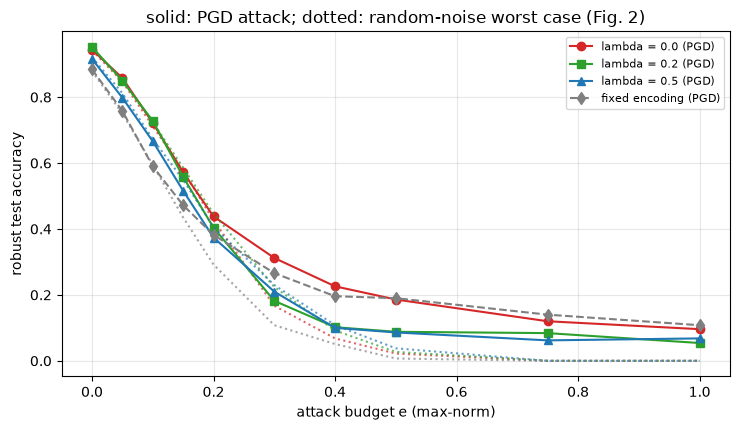

In [14]:
def pgd_robust_acc(fscalar, X, y, e, steps, seed):
    rng = np.random.default_rng(seed)
    xa = X + rng.uniform(-e, e, X.shape); ok = (sgn(fscalar(xa)) == y)
    alpha = 2.5 * e / steps
    for _ in range(steps):
        gr = grad(lambda z: anp.sum((fscalar(z) - y) ** 2))(xa)
        xa = X + np.clip(xa + alpha * np.sign(gr) - X, -e, e)
        ok &= (sgn(fscalar(xa)) == y)
    return ok.mean()

Xp, yp = Xro[:N_PGD_TEST], yro[:N_PGD_TEST]
PGD = {}
t0 = time.time()
for model, lam in MODELS_ROB:
    v1 = BEST[(0, model, lam)][None]; fw = FWD[model]
    PGD[(model, lam)] = np.array([(sgn(fw(v1, Xp)[0]) == yp).mean() if e == 0 else pgd_robust_acc(lambda z: fw(v1, z)[0], Xp, yp, e, N_PGD_STEPS, SEED + 31 + k)
                                  for k, e in enumerate(EPS_GRID)])
rnd_sub = {k: ROB[(0,) + k] for k in MODELS_ROB}
pgd_df = pd.DataFrame({LBL[k]: PGD[k] for k in MODELS_ROB}, index=EPS_GRID); pgd_df.index.name = "noise level e"
print(f"PGD robust accuracy on the first {N_PGD_TEST} test points (done in {time.time() - t0:.0f} s):"); print(pgd_df.round(3).to_string())
fig, ax = plt.subplots(1, 1, figsize=(7.5, 4.4))
for k in MODELS_ROB:
    c, st = STY[k]; ax.plot(EPS_GRID, PGD[k], st, color=c, label=LBL[k] + " (PGD)"); ax.plot(EPS_GRID, ROB[(0,) + k], ":", color=c, alpha=0.7)
ax.set_xlabel("attack budget e (max-norm)"); ax.set_ylabel("robust test accuracy"); ax.set_title("solid: PGD attack; dotted: random-noise worst case (Fig. 2)"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

## 9. Classical baselines on identical inputs

The paper compares only quantum models. For an honest reading, three classical competitors are trained on **exactly the same 200 training points** (raw coordinates, no extra features) and evaluated on the same test sets and with the same worst-case noise protocol:

* a small tanh network `2-16-16-1` (`f = tanh(...)`, output in `[-1, 1]` like the quantum expectation value) trained with the same ADAM schedule, the same MSE loss, the same "best cost over all restarts and epochs" selection, and the **same kind of regulariser**: `lambda_c * sum_i ||W_i||_F^2`, the classical counterpart of `lambda sum_j ||w_j||^2` (weight decay). Its Lipschitz bound is the product of the spectral norms `||W_1|| ||W_2|| ||W_3||` (tanh is 1-Lipschitz); the Frobenius norm used in the penalty is an upper bound on the spectral norm (`# CHOICE:`);
* `SVC` with an RBF kernel (default `C = 1`, `gamma = "scale"`) and a `RandomForestClassifier` (100 trees).

  [classical tanh network] trained 72 models x 500 epochs in 59 s


 lam_c        L  train_acc  test_acc  train_mse  test_mse
 0.000 374.7210       1.00    0.9798     0.0017    0.0605
 0.001  68.6303       1.00    0.9813     0.0341    0.0612
 0.003  34.7055       0.99    0.9736     0.0751    0.1002
 0.010  16.3340       0.98    0.9583     0.1592    0.1782
 0.020  10.8392       0.97    0.9564     0.2399    0.2510
 0.030   8.1942       0.97    0.9557     0.3161    0.3212


test accuracy on the 10 000-point (or reduced) generalisation set: {'SVC (rbf)': np.float64(0.9316), 'random forest': np.float64(0.9444)}


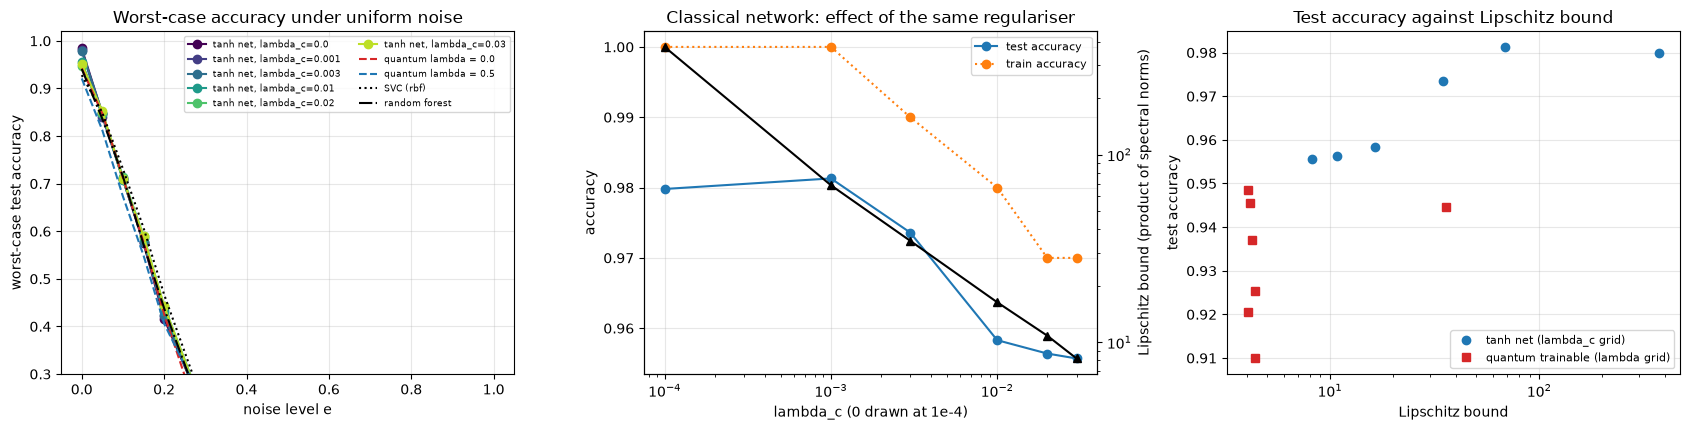

               tanh net lambda_c=0.0  tanh net lambda_c=0.001  tanh net lambda_c=0.003  tanh net lambda_c=0.01  tanh net lambda_c=0.02  tanh net lambda_c=0.03  SVC (rbf)  random forest
noise level e                                                                                                                                                                           
0.00                           0.984                    0.981                    0.979                   0.955                   0.948                   0.951      0.928          0.941
0.05                           0.847                    0.840                    0.849                   0.846                   0.849                   0.852      0.849          0.836
0.10                           0.709                    0.711                    0.709                   0.707                   0.714                   0.709      0.731          0.715
0.15                           0.575                    0.577              

In [15]:
SZ = [(H_CL, 2), (H_CL,), (H_CL, H_CL), (H_CL,), (1, H_CL), (1,)]
P_MLP = int(sum(np.prod(s) for s in SZ))
def mlp_unpack(v):
    R = v.shape[0]; o = 0; out = []
    for s in SZ:
        n = int(np.prod(s)); out.append(v[:, o:o + n].reshape((R,) + s)); o += n
    return out
def fwd_mlp(v, x):
    W1, b1, W2, b2, W3, b3 = mlp_unpack(v)
    h = anp.tanh(anp.matmul(x[None], anp.swapaxes(W1, 1, 2)) + b1[:, None, :])
    h = anp.tanh(anp.matmul(h, anp.swapaxes(W2, 1, 2)) + b2[:, None, :])
    return anp.tanh(anp.matmul(h, anp.swapaxes(W3, 1, 2)) + b3[:, None, :])[..., 0]
def reg_mlp(v):
    W1, b1, W2, b2, W3, b3 = mlp_unpack(v); return anp.sum(W1 ** 2, (1, 2)) + anp.sum(W2 ** 2, (1, 2)) + anp.sum(W3 ** 2, (1, 2))
def lip_mlp(v):
    W1, b1, W2, b2, W3, b3 = mlp_unpack(np.atleast_2d(v)); sn = lambda W: np.linalg.svd(W, compute_uv=False)[:, 0]
    return sn(W1) * sn(W2) * sn(W3)

rng_c = np.random.default_rng(SEED + 55)
def init_mlp(n):
    parts = []
    for s in SZ:
        parts.append(rng_c.normal(0, 1 / np.sqrt(s[-1]), (n,) + s).reshape(n, -1) if len(s) == 2 else np.zeros((n, s[0])))   # CHOICE: N(0, 1/fan_in), zero biases
    return np.hstack(parts)
init_c = init_mlp(N_RUNS)
lam_rows_c = np.repeat(np.array(LAMBDAS_CL, float), N_RUNS); v0c = np.tile(init_c, (len(LAMBDAS_CL), 1))
bvc, bcc, hcc, hmc = adam_train(fwd_mlp, reg_mlp, v0c, lam_rows_c, Xtr, ytr, EPOCHS_CL, LR_CL, tag="classical tanh network")
selc = pick_best(bvc, bcc, lam_rows_c, LAMBDAS_CL, N_RUNS)
CL = []
for lam in LAMBDAS_CL:
    v1 = bvc[selc[lam]][None]
    CL.append(dict(lam_c=lam, L=float(lip_mlp(v1)[0]), train_acc=acc_of(fwd_mlp, v1, Xtr, ytr)[0], test_acc=acc_of(fwd_mlp, v1, Xge, yge)[0],
                   train_mse=((predict(fwd_mlp, v1, Xtr)[0] - ytr) ** 2).mean(), test_mse=((predict(fwd_mlp, v1, Xge)[0] - yge) ** 2).mean()))
CL = pd.DataFrame(CL); print(CL.round(4).to_string(index=False))

ROB_CL = {lam: robust_curve(lambda Z, v1=bvc[selc[lam]][None]: sgn(predict(fwd_mlp, v1, Z)[0]), Xro, yro, EPS_GRID, N_NOISE, SEED + 500)[0] for lam in LAMBDAS_CL}
svc = SVC(kernel="rbf", C=1.0, gamma="scale").fit(Xtr, ytr); rf = RandomForestClassifier(n_estimators=100, random_state=SEED, n_jobs=1).fit(Xtr, ytr)
ROB_SK = {"SVC (rbf)": robust_curve(lambda Z: svc.predict(Z), Xro, yro, EPS_GRID, N_NOISE, SEED + 500)[0],
          "random forest": robust_curve(lambda Z: rf.predict(Z), Xro, yro, EPS_GRID, N_NOISE, SEED + 500)[0]}
SK_TEST = {"SVC (rbf)": (svc.predict(Xge) == yge).mean(), "random forest": (rf.predict(Xge) == yge).mean()}
print("test accuracy on the 10 000-point (or reduced) generalisation set:", {k: round(v, 4) for k, v in SK_TEST.items()})

fig, ax = plt.subplots(1, 3, figsize=(17, 4.4))
cmc = plt.cm.viridis(np.linspace(0, 0.9, len(LAMBDAS_CL)))
for lam, col in zip(LAMBDAS_CL, cmc): ax[0].plot(EPS_GRID, ROB_CL[lam], "o-", color=col, label=f"tanh net, lambda_c={lam}")
for k in (("trainable", 0.0), ("trainable", 0.5)): ax[0].plot(EPS_GRID, ROB[(0,) + k], "--", color=STY[k][0], label="quantum " + LBL[k])
for (name, cur), st in zip(ROB_SK.items(), ("k:", "k-.")): ax[0].plot(EPS_GRID, cur, st, label=name)
ax[0].set_xlabel("noise level e"); ax[0].set_ylabel("worst-case test accuracy"); ax[0].set_ylim(0.3, 1.02); ax[0].legend(fontsize=6.5, ncol=2); ax[0].set_title("Worst-case accuracy under uniform noise")
ax[1].plot(CL.lam_c.where(CL.lam_c > 0, 1e-4), CL.test_acc, "o-", label="test accuracy"); ax[1].plot(CL.lam_c.where(CL.lam_c > 0, 1e-4), CL.train_acc, "o:", label="train accuracy")
ax[1].set_xscale("log"); ax[1].set_xlabel("lambda_c (0 drawn at 1e-4)"); ax[1].set_ylabel("accuracy"); ax[1].legend(fontsize=8)
a2 = ax[1].twinx(); a2.plot(CL.lam_c.where(CL.lam_c > 0, 1e-4), CL.L, "k^-"); a2.set_yscale("log"); a2.set_ylabel("Lipschitz bound (product of spectral norms)"); a2.grid(False); ax[1].set_title("Classical network: effect of the same regulariser")
ax[2].plot(CL.L, CL.test_acc, "o", color="#1f77b4", label="tanh net (lambda_c grid)"); ax[2].plot(d0.L, d0.test_acc, "s", color="#d62728", label="quantum trainable (lambda grid)")
ax[2].set_xscale("log"); ax[2].set_xlabel("Lipschitz bound"); ax[2].set_ylabel("test accuracy"); ax[2].legend(fontsize=8); ax[2].set_title("Test accuracy against Lipschitz bound")
plt.tight_layout(); plt.show()
cl_df = pd.DataFrame({f"tanh net lambda_c={lam}": ROB_CL[lam] for lam in LAMBDAS_CL}, index=EPS_GRID); cl_df["SVC (rbf)"] = ROB_SK["SVC (rbf)"]; cl_df["random forest"] = ROB_SK["random forest"]
cl_df.index.name = "noise level e"; print(cl_df.round(3).to_string())

## 10. Paper versus this notebook

Every numerical or qualitative claim of the paper that the experiment can test is listed with the rule used for the verdict. Verdicts: **reproduced** (rule satisfied), **not reached** (rule violated), **cannot be checked** (the paper gives no numbers or constants). Qualitative claims are judged on the mean over the training-set draws when there are several (the draw-0 value is shown as well). Lipschitz values depend on unreported choices (loss, initialisation), so they count as reproduced within a factor `[0.7, 1.3]`.

In [16]:
def verdict(ok): return "reproduced" if ok else "not reached"
def ratio_verdict(paper, mine, lo=0.7, hi=1.3):
    r = mine / paper
    return "reproduced" if lo <= r <= hi else ("exceeded (larger)" if r > hi else "not reached (smaller)")
MEAN_ACC = TR.groupby("lam").test_acc.mean(); MEAN_L = TR.groupby("lam").L.mean()
L0 = {lam: float(TR[(TR.draw == 0) & (TR.lam == lam)].L.iloc[0]) for lam in LAMBDAS_GEN}
at = lambda df, col, e: float(df.loc[e, col])
E = list(EPS_GRID); big = [e for e in E if e >= 0.4]; small = [e for e in E if e <= 0.1]; high = [e for e in E if e >= 0.6]
A0, A2, A5, AF = (mean_df[LBL[k]] for k in MODELS_ROB)
lam_star = float(MEAN_ACC.idxmax()); acc_star = float(MEAN_ACC.max())
fx_range = f0.test_acc.max() - f0.test_acc.min(); tr_range = d0.test_acc.max() - d0.test_acc.min()
fx_mean_best = float(FX.groupby("lam").test_acc.mean().max())
B0, B2, B5, BF = (means_df[LBL[k]] for k in MODELS_ROB)
def rob_flags(A0, A2, A5, AF):
    return dict(
        e0=A5[0.0] < A0[0.0],
        big=np.mean([A5[e] > A0[e] for e in big]) >= 0.75,
        fixed_worst=np.mean([AF[e] <= min(A0[e], A2[e], A5[e]) for e in high]) >= 0.75,
        comparable=max(abs(AF[e] - A5[e]) for e in small) <= 0.05,
        l02=np.mean([A2[e] >= A0[e] - 1e-12 for e in E]) >= 0.8 and A2[0.0] > A0[0.0])
FA, FB = rob_flags(A0, A2, A5, AF), rob_flags(B0, B2, B5, BF)
rows = []
def add(claim, paper, mine, v, rule, alt=""): rows.append(dict(claim=claim, paper=paper, notebook=mine, verdict=v, rule=rule, alt_reading_B=alt))
add("Fig. 2: L of the fixed encoding", "56.55", f"{LIP_FIXED:.2f}", verdict(abs(LIP_FIXED - 56.55) < 0.01), "exact (18 pi)")
for lam, pv in ((0.0, 40.66), (0.2, 4.0), (0.5, 3.67)):
    add(f"Fig. 2: L of the trained model, lambda={lam}", f"{pv}", f"draw0 {L0[lam]:.2f} | mean {MEAN_L[lam]:.2f}", ratio_verdict(pv, L0[lam]), "draw 0 within a factor [0.7, 1.3]")
rho_L = spearmanr(MEAN_L.index, MEAN_L.values).statistic
add("Fig. 3: L decreases with lambda", "monotone decrease", f"Spearman(lambda, mean L) = {rho_L:.2f}; draw 0 L(0)>L(0.2)>L(0.5): {L0[0.0] > L0[0.2] > L0[0.5]}", verdict(rho_L <= -0.85 and L0[0.0] > L0[0.2] > L0[0.5]), "Spearman <= -0.85 and draw 0 strictly ordered")
add("Fig. 2: at e=0, lambda=0.5 is less accurate than lambda=0", "acc(0.5) < acc(0)", f"mean {A5[0.0]:.3f} vs {A0[0.0]:.3f} (draw 0: {at(rob_df, LBL[('trainable', 0.5)], 0.0):.3f} vs {at(rob_df, LBL[('trainable', 0.0)], 0.0):.3f})", verdict(FA["e0"]), "mean over draws", verdict(FB["e0"]))
add("Fig. 2: at larger noise, lambda=0.5 beats lambda=0", "acc(0.5) > acc(0) at high noise", f"holds at {np.mean([A5[e] > A0[e] for e in big]):.0%} of the noise levels >= 0.4", verdict(FA["big"]), ">= 75% of noise levels >= 0.4", verdict(FB["big"]))
add("Fig. 2: fixed encoding is the worst at high noise", "lowest curve", f"lowest of the four at {np.mean([AF[e] <= min(A0[e], A2[e], A5[e]) for e in high]):.0%} of the noise levels >= 0.6", verdict(FA["fixed_worst"]), "lowest at >= 75% of noise levels >= 0.6", verdict(FB["fixed_worst"]))
add("Fig. 2: fixed encoding comparable to lambda=0.5 at small noise", "comparable", f"max |difference| for e <= 0.1: {max(abs(AF[e] - A5[e]) for e in small):.3f}", verdict(FA["comparable"]), "difference <= 0.05 for e <= 0.1", verdict(FB["comparable"]))
add("Fig. 2: lambda=0.2 almost always beats lambda=0, also at small noise", "acc(0.2) >= acc(0) almost always, higher at small noise", f"acc(0.2) >= acc(0) at {np.mean([A2[e] >= A0[e] - 1e-12 for e in E]):.0%} of levels; at e=0: {A2[0.0]:.3f} vs {A0[0.0]:.3f}", verdict(FA["l02"]), ">= 80% of levels and higher at e=0", verdict(FB["l02"]))
add("Fig. 3: sweet spot of lambda near 0.15", "max test accuracy at lambda = 0.15", f"argmax lambda = {lam_star} (mean) | {lam_best0} (draw 0)", verdict(0.05 <= lam_star <= 0.3 and lam_star > 0), "interior argmax in [0.05, 0.3]")
add("Fig. 3: regularisation improves test accuracy over lambda=0", "acc(0.15) > acc(0)", f"best mean {acc_star:.4f} vs lambda=0: {MEAN_ACC[0.0]:.4f} (gap {acc_star - MEAN_ACC[0.0]:+.4f})", verdict(acc_star > MEAN_ACC[0.0]), "best mean test accuracy > unregularised")
add("Fig. 3: test accuracy range", "0.88 to 1.00", f"{MEAN_ACC.min():.3f} to {MEAN_ACC.max():.3f}", verdict(MEAN_ACC.min() >= 0.88 and MEAN_ACC.max() <= 1.0), "all mean accuracies in [0.88, 1.00]")
add("Fig. 3: too large a lambda lowers accuracy again", "decrease beyond the optimum", f"acc(0.5) = {MEAN_ACC[0.5]:.4f} vs best {acc_star:.4f}", verdict(MEAN_ACC[0.5] < acc_star), "acc(0.5) < best")
add("Theorem IV.1: smaller L goes with smaller generalisation gap", "bound C1*L + C2/sqrt(n)", f"Spearman(L, test-train MSE gap) = {rho_gap.statistic:.2f} (p = {rho_gap.pvalue:.2g}); C1, C2 not given", verdict(rho_gap.statistic > 0.3 and rho_gap.pvalue < 0.05) + " (trend only)", "trend: rho > 0.3 and p < 0.05; constants cannot be checked")
add("Eq. 5: the bound is valid", "|f(x)-f(x')| <= L||x-x'||", f"max gradient norm / L = {BND.tightness.max():.3f}; max pair ratio = {BND.max_pair_ratio.max():.3f}", verdict(bool((BND.max_pair_ratio <= 1).all() and (BND.tightness <= 1).all())), "never exceeded (also asserted)")
add("Sect. V / Fig. 6: L of the fixed encoding is constant under lambda_phi", "constant", f"L = {LIP_FIXED:.2f} for all lambda_phi (set by the fixed w_j)", verdict(True), "by construction, shown in the table of section 6")
add("Fig. 6: fixed encoding is much less sensitive to lambda_phi", "weak dependence", f"range of test accuracy: fixed {fx_range:.4f} vs trainable {tr_range:.4f} (draw 0)", verdict(fx_range < tr_range), "smaller range than the trainable model (draw 0)")
add("Fig. 3 vs 6: trainable encoding has the higher test accuracy", "significantly higher", f"best mean test accuracy: trainable {acc_star:.4f} vs fixed {fx_mean_best:.4f}", verdict(acc_star > fx_mean_best + 0.02), "trainable exceeds fixed by > 0.02")
add("Fig. 5: boundary smoother under regularisation", "smoother", f"mean |grad f|: lambda=0.15 {rough[('trainable', 0.15)]:.3f} vs lambda=0 {rough[('trainable', 0.0)]:.3f}", verdict(rough[("trainable", 0.15)] < rough[("trainable", 0.0)]), "smaller mean gradient magnitude (proxy)")
add("Fig. 5: fixed encoding does not capture the circle", "inaccurate boundary", f"fixed (draw 0) test accuracy {f0.test_acc.iloc[0]:.3f} vs trainable lambda=0.15 {float(d0[d0.lam == 0.15].test_acc.iloc[0]):.3f}", verdict(f0.test_acc.iloc[0] < float(d0[d0.lam == 0.15].test_acc.iloc[0]) - 0.02), "fixed lower by > 0.02")
VER = pd.DataFrame(rows)
pd.set_option("display.max_colwidth", 90)
print(VER[["claim", "paper", "notebook", "verdict", "alt_reading_B"]].to_string(index=False))
print(); print("counts:", VER.verdict.str.replace(r" \(.*\)", "", regex=True).value_counts().to_dict())

                                                                 claim                                                   paper                                                             notebook                  verdict alt_reading_B
                                       Fig. 2: L of the fixed encoding                                                   56.55                                                                56.55               reproduced              
                            Fig. 2: L of the trained model, lambda=0.0                                                   40.66                                             draw0 35.70 | mean 40.39               reproduced              
                            Fig. 2: L of the trained model, lambda=0.2                                                     4.0                                               draw0 4.17 | mean 4.10               reproduced              
                            Fig. 2: L of the trained model, 

In [17]:
# Extra checks (not claims of the paper): PGD attack and the classical network with the same regulariser
pg = pgd_df
ex = []
hi_e = [e for e in EPS_GRID if e >= 0.25]
ex.append(("PGD attack: lambda=0.5 more robust than lambda=0", f"PGD accuracy higher at {np.mean([pg.loc[e, LBL[('trainable', 0.5)]] > pg.loc[e, LBL[('trainable', 0.0)]] for e in hi_e]):.0%} of budgets >= 0.25",
           "same trend as under random noise" if np.mean([pg.loc[e, LBL[('trainable', 0.5)]] > pg.loc[e, LBL[('trainable', 0.0)]] for e in hi_e]) >= 0.75 else "different from random noise"))
ex.append(("PGD attack: fixed encoding", f"PGD accuracy at the largest budget: {pg.iloc[-1][LBL[('fixed', 0.0)]]:.3f} (random noise: {rob_df.iloc[-1][LBL[('fixed', 0.0)]]:.3f})", "PGD is at least as strong as noise" if (pg.iloc[-1] <= rob_df.iloc[-1] + 0.05).all() else "PGD weaker than noise on this subset"))
cl0, clb = CL.iloc[0], CL.loc[CL.test_acc.idxmax()]
ex.append(("Classical network: same regulariser lowers its Lipschitz bound", f"L: {cl0.L:.1f} (lambda_c=0) -> {CL.L.min():.1f} (lambda_c={CL.loc[CL.L.idxmin(), 'lam_c']})", "yes" if CL.L.min() < cl0.L else "no"))
ex.append(("Classical network: best test accuracy vs quantum", f"tanh net {clb.test_acc:.4f} (lambda_c={clb.lam_c}) | quantum best {d0.test_acc.max():.4f} | SVC {SK_TEST['SVC (rbf)']:.4f} | RF {SK_TEST['random forest']:.4f}", "classical baseline is " + ("at least as good" if max(clb.test_acc, SK_TEST['SVC (rbf)']) >= d0.test_acc.max() - 0.005 else "worse")))
EX = pd.DataFrame(ex, columns=["extra check", "numbers", "outcome"]); print(EX.to_string(index=False))
print(f"\nTotal wall-clock time of this notebook: {(time.time() - T0) / 60:.1f} min  (FAST_MODE={FAST_MODE})")

                                                   extra check                                                                         numbers                                outcome
              PGD attack: lambda=0.5 more robust than lambda=0                                    PGD accuracy higher at 0% of budgets >= 0.25            different from random noise
                                    PGD attack: fixed encoding                 PGD accuracy at the largest budget: 0.108 (random noise: 0.000)   PGD weaker than noise on this subset
Classical network: same regulariser lowers its Lipschitz bound                                    L: 374.7 (lambda_c=0) -> 8.2 (lambda_c=0.03)                                    yes
              Classical network: best test accuracy vs quantum tanh net 0.9813 (lambda_c=0.001) | quantum best 0.9486 | SVC 0.9316 | RF 0.9444 classical baseline is at least as good

Total wall-clock time of this notebook: 31.8 min  (FAST_MODE=False)


## 11. Reading the paper critically

All numbers below are from the full run (`FAST_MODE = False`: 12 restarts and 200 epochs for the main training set, two further training sets with 3 restarts, 200 noise samples per test point for the main set; about 32 minutes on a shared laptop CPU). Other runs with different seeds or a different CPU will differ in the third digit; the qualitative picture below is what the notebook supports.

**What is solid.**

* *The theory and its constants.* The Lipschitz bound `L = 2 ||M|| sum_j ||w_j|| ||H_j||` is never violated: the largest gradient norm found is at most 0.53 `L` for the trained models (0.13 `L` for the fixed encoding), so the bound is valid but loose by a factor of about 2 (trained) to 8 (fixed), as expected for a worst case over all inputs and all parameters. For the fixed encoding `L = 18 pi = 56.55` is exact. The trained values (`40.4 / 4.1 / 4.0` averaged over three training sets for `lambda = 0 / 0.2 / 0.5`; draw 0: `35.7 / 4.17 / 4.06`) agree with the paper's `40.66 / 4.0 / 3.67` within the 30 % tolerance. The regulariser does its job on `L`: it drops by a factor of 6 (mean over draws) to 8 (draw 0) between `lambda = 0` and `lambda = 0.05` and then plateaus at about 4. That plateau is itself informative: a model that must separate a circle from its surroundings with this circuit apparently needs `L` of about 4, and a stronger penalty mostly costs accuracy (`lambda = 0.5`: 0.89 on average).
* *Robustness.* Under the literal "worst case over 200 noise samples per point" (reading A) the regularised models are more robust than the unregularised one once the noise is not tiny: averaged over the three training sets the accuracy at `e = 0.3` is 0.21 (`lambda = 0`), 0.27 (`0.2`), 0.28 (`0.5`) and 0.15 (fixed encoding); at `e = 0` the order is reversed for `lambda = 0.5` (0.89 against 0.95), as the paper says. The fixed-encoding model, whose bound is the largest, is the worst of the four at every noise level above 0 (mean over draws). Under reading B (worst test-set accuracy over whole-test-set noise realisations) the curves have the range of the paper's Fig. 2 (about 0.5 at `e = 1`), which suggests that the paper may have used B; the verdict table shows both.
* *Fixed versus trainable encoding.* The trainable encoding is better than the fixed one (best mean test accuracy 0.949 against 0.912), and its decision boundary under regularisation is the smooth circle of Fig. 5 while the fixed-encoding boundary is irregular.

**What is not reproduced.**

* *The generalisation "sweet spot" (Fig. 3).* The paper finds the best test accuracy at `lambda = 0.15` and a clear gain over `lambda = 0`. Here the clean test accuracy varies only between 0.91 and 0.95 for `lambda <= 0.3` and the unregularised model is as good as any regularised one (mean over three training sets: 0.949 +- 0.004 at `lambda = 0`, 0.942 +- 0.008 at 0.15, 0.944 +- 0.007 at 0.2). Differences of one or two points are inside the spread over restarts and training sets, so with 200 training points the benefit of regularisation for *clean* accuracy cannot be confirmed. Theorem IV.1 predicts that a smaller `L` goes with a smaller generalisation gap; the Spearman correlation between `L` and the test-minus-train MSE gap has the right sign (0.40) but is not significant (p = 0.07, 21 models). The constants `C1`, `C2` of the bound are not in the paper, so the bound itself cannot be tested.
* *The model fits the circle less well than the paper's.* Even without regularisation the selected model reaches only 0.95 training accuracy (MSE 0.26), so the regime "the unregularised model overfits" that the paper's discussion presupposes is not reached. Loss, initialisation and batching are not stated in the paper; in side experiments outside this notebook, mini-batches of 10 or 20 points and a cross-entropy or hinge loss did not give a better fit on this circuit, but this was not explored systematically. If your own choices fit the circle better, the sweet spot may appear.
* *Small claims about relative ordering.* The fixed encoding is not "comparable to `lambda = 0.5` at small noise" under reading A (it is 0.08 lower at `e = 0.1`; under reading B it is), `lambda = 0.2` is not better than `lambda = 0` at `e = 0` (0.94 against 0.95 on average) although it is at most other noise levels, and the fixed encoding is not less sensitive to its regulariser than the trainable one in draw 0 (it collapses at `lambda_phi = 0.1`, so the range is dominated by that point).

**Cautions that go beyond the paper.**

1. *Random noise is not an adversary.* With a 10-step PGD attack the picture changes: for budgets of 0.3 and above the unregularised model keeps more accuracy (0.31 at `e = 0.3`) than `lambda = 0.2` (0.18) and `lambda = 0.5` (0.21). PGD with so few steps is a weak attack here (at `e = 0.5` it leaves about 0.1 to 0.2 accuracy while 200 random samples leave almost none), so this is not proof that regularisation hurts, but it shows that a Lipschitz bound is a statement about the worst case, and the random-noise protocol is not the worst case. An attack that exploits the whole ball would be needed to decide.
2. *Classical models do about as well.* A 2-16-16-1 tanh network trained on the same 200 points reaches 0.98 test accuracy, SVC 0.93 and a random forest 0.94, against 0.95 for the best quantum model. The same weight-decay regulariser lowers the network's Lipschitz bound from 375 to 8, yet its worst-case noise curve barely moves: at `e = 0.3` the accuracy is 0.21 to 0.22 for every `lambda_c`, and equal to that of SVC and random forest. Under random noise the worst-case accuracy of this task is therefore dominated by the geometry of the circle (a point close to the boundary is flipped by any model that is correct), not by the Lipschitz constant, and a small `L` is neither necessary nor sufficient for the robustness the paper measures. The paper does not claim a quantum advantage, and nothing here suggests one.
3. *One training set is a small sample.* The paper's curves come from one draw of 200 points; the spread over three draws is of the same size as most of the effects discussed above. The 12 restarts per `lambda`, and the selection of the best run by training cost, favour models that fit the particular 200 points.
4. *The regulariser's scale depends on conventions.* With `||H_j|| = 1/2` the penalty is `lambda / 4 sum ||w_j||^2`; if the authors' code used `||H_j|| = 1` the same `lambda` is four times stronger. The close agreement of the resulting `L` values with the paper (4.17 and 4.06 against 4.0 and 3.67) suggests the convention used here is not far off, but the plateau of `L` means `L` cannot discriminate between values of `lambda` between 0.05 and 0.5.
5. *Cost.* The fast simulator is exact (asserted against `default.qubit` and `lightning.qubit` in value and gradient); the 100+ trained models would take many hours through QNodes. Nothing here depends on that simplification, but it means the notebook trains with autograd, not with the paper's adjoint method.

## 12. Exercises

1. **Different norms.** The paper mentions that a 1-norm penalty could sparsify the encoding. Replace `reg_train` by `lambda * sum_j ||w_j||_1 ||H_j||` (the bound then holds for the 1-norm on the inputs) and compare sparsity of `W` and test accuracy.
2. **Offsets do not matter for the bound.** Add a penalty on the offsets `theta_j` and verify numerically that `L` is unchanged while accuracy changes.
3. **Layers and qubits.** Rerun with 1, 2, 4 layers (`N_LAYERS`) and plot the best test accuracy and the Lipschitz bound against depth. The fast simulator assumes 3 qubits (`RING`, `SIGN`, `E0`); generalising it is part of the exercise.
4. **Adaptive attacker.** Replace the PGD loss `(f - y)^2` by the margin `-y f` and use more steps and restarts. Does the ranking of the four models in section 8 change?
5. **A tighter bound.** Compute `L` from the *actual* generators of each gate with a data-dependent bound (for instance the largest singular value of the Jacobian of the first-layer angles), and compare with the paper's `L` and with the largest gradient norm found in section 7.